# Utilizing SHAP to Explain an XGBoost Model for Breast Cancer — Implementation

**Implementation phase of the research proposal** *“Utilizing SHAP to Explain XGBoost Algorithm for Breast Cancer Diagnosis”* (Dept. of Computer Science, University of Jos).
Data: **TCGA-BRCA** (The Cancer Genome Atlas) clinical records, as specified in Chapter 3.

| Proposal objective | Where it is implemented |
|---|---|
| **Obj. 1** – conceptual framework for integrating SHAP into a healthcare-AI pipeline | pipeline figure below; the dashboard realises the integration points |
| **Obj. 2** – diagnostic performance: accuracy, precision, recall, F1, AUC | §5 – §6 (held-out test set + repeated cross-validation, with confidence intervals) |
| **Obj. 3** – SHAP analysis: most influential clinical features, strengths/weaknesses | §7 (global, local, interaction), §9 (stability, clinical alignment) |
| **Obj. 4** – perceived interpretability / trust (user study) | The interactive **Streamlit dashboard** (`app.py`) is the study instrument; the notebook exports everything it needs (§11) |
| **Extension requested for this implementation** – *how do features affect predictions for Black patients?* | **§6.1 and §8 – a dedicated race-equity analysis** (subgroup performance, subgroup SHAP, risk-gap decomposition, counterfactuals, stability) |

> **Read this first — three honest deviations from the proposal text, and why**
>
> 1. **The prediction target.** Chapter 3 says “benign vs. malignant”. TCGA-BRCA contains *only malignant* cases (no benign lesions), and its clinical table has no benign/malignant label, so that task cannot be built from it without manufacturing a label. The closest clinically meaningful, *recall-critical* supervised task the data genuinely supports is **mortality risk: will the patient die during follow-up (overall-survival event)?** A false negative here (a high-risk patient scored as low-risk) is exactly the costly error the proposal is concerned with, so the recall-first design carries over unchanged. Section 1 documents the candidate targets I compared before choosing this one.
> 2. **Race is deliberately included as an input.** For deployment, one would usually think hard before feeding race into a clinical model. For an *explainability audit* — which is what you asked for — it must be visible to the explainer so that we can measure what the model does with it, and we also train a **race-blind** twin to see what changes (§8.7).
> 3. **Informative missingness was found and neutralised.** In TCGA, *“not recorded”* for HER2, nodal status, M-stage and menopausal status is itself strongly associated with death (33 % vs 11 % for HER2) — a registry/documentation artefact, not biology. A model fed those NaNs learns “undocumented ⇒ dies” and looks better than it is. §1.2 shows the audit and §6.2 the before/after; the final model uses clinical conventions (MX→M0, NX→N0, unrecorded HER2→not positive) and drops menopausal status (collinear with age, ρ = 0.70).
> 4. **Small-sample reality.** Black patients are 18 % of the cohort (n≈179, ≈29 deaths). Every subgroup number is therefore reported with a **bootstrap 95 % CI**, and the SHAP findings are checked for **stability across 100 re-trainings**. Where the evidence is weak, the notebook says so.

### Pipeline (conceptual framework – Objective 1)

```
 TCGA-BRCA clinical data ──► cleaning & encoding ──► stratified train / val / test
 (UCSC Xena + cBioPortal)    (NaN kept, no leakage)   (stratified on race × outcome)
                                                            │
        ┌───────────────────────────────────────────────────┘
        ▼
 XGBoost  ◄── hyper-parameter search (CV on train) ── early stopping (validation) ── recall-first threshold
        │
        ├──► Evaluation: ROC/PR, calibration, subgroup metrics (by race) with bootstrap CIs
        │
        └──► SHAP (TreeExplainer) ─► global ▸ local ▸ interaction ▸ subgroup (Black vs White)
                       │                                   │
                       │                                   └─► stability (100 bootstraps) & clinical-alignment checks
                       ▼
              Streamlit dashboard: enter a patient → risk + SHAP waterfall · explore cohort · race-equity view
```

## 0. Setup

In [1]:
import sys, json, warnings, time, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
import seaborn as sns
import shap, xgboost as xgb, sklearn
from scipy import stats
from IPython.display import display, Markdown

from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, RandomizedSearchCV,
                                     cross_val_score)
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             brier_score_loss, confusion_matrix, accuracy_score, f1_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from scipy.stats import loguniform, randint, uniform
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from brca_xai import *            # data loading, FEATURES, encode(), LABELS ...

SEED = 42
rng = np.random.default_rng(SEED)
ART = ROOT / "artifacts"; ART.mkdir(exist_ok=True)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

# Okabe-Ito colour-blind-safe palette; Black patients get the high-contrast colour throughout
RC = {"Black": "#D55E00", "White": "#0072B2", "Asian": "#009E73"}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.gcf().savefig(FIG / f"{name}.png", bbox_inches="tight")

print(f"python {sys.version.split()[0]} | xgboost {xgb.__version__} | shap {shap.__version__} | sklearn {sklearn.__version__} | pandas {pd.__version__}")

C:\Users\Segun\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python 3.12.10 | xgboost 3.2.0 | shap 0.53.0 | sklearn 1.8.0 | pandas 3.0.2


## 1. Data acquisition, cleaning and target definition

Two public TCGA tables are joined on the patient barcode (`brca_xai/data.py` does the work; the module is shared with the dashboard so training-time and serving-time encodings are identical):

* **UCSC Xena** `TCGA.BRCA` clinical matrix → ER / PR / HER2 status, histology, menopausal status (this is the source the proposal cites).
* **cBioPortal PanCancer Atlas 2018** patient table → **self-reported race**, age, pathologic T/N/M, overall-survival status.

**Design decisions** (each one protects against a specific failure mode):

| Decision | Reason |
|---|---|
| ER / PR / histology gaps are **kept as NaN**, not imputed | XGBoost and TreeSHAP both handle missingness natively, and the audit in §1.2 shows their missingness carries no outcome signal. Where it *does* (HER2, N, M) the encoding applies the clinical default instead. |
| Features are limited to what is known **at diagnosis** (age, race, TNM, ER/PR/HER2, histology) | No treatment, follow-up or calendar-year variables → avoids label leakage (year of diagnosis, for example, proxies follow-up length). |
| AJCC *stage group* is **not** a feature (T, N, M are) | Stage is a deterministic function of TNM; including both splits SHAP credit arbitrarily between collinear columns. |
| Menopausal status is **not** a feature | Collinear with age (ρ = 0.70) and its “missing” category is a strong outcome artefact (§1.2). |
| PAM50 subtype is **not** a feature | Requires gene-expression assay, not routine clinical data, and is collinear with ER/PR/HER2. It is kept for descriptive tables only. |
| Cohort: **female**, race ∈ {White, Black, Asian} | 12 male cases and 1 American-Indian case cannot support any inference. 90 patients with unrecorded race are excluded (race-stratified analysis is impossible for them). |

The candidate targets I screened (5-fold CV AUC, XGBoost, protected encoding of §1.2): *death during follow-up* **0.66** · *basal-like PAM50* 0.70 and *triple-negative* 0.69 (both only when ER/PR/HER2 are withheld, which makes them circular: a clinician simply reads the receptor result off the pathology report instead of predicting it from age and race) · *late stage III–IV from non-TNM features* **0.56, essentially unpredictable**. Death is the only target that is non-circular, has usable signal, and where false negatives have a direct clinical consequence.

In [2]:
clean = load_clean()
X = encode(clean)
y = clean[TARGET].astype(int).values
is_black = (clean.race == "Black").values
is_white = (clean.race == "White").values
strata = (clean.race + "_" + clean[TARGET].astype(int).astype(str)).values   # used for stratified CV / bootstrap

print(f"Analysis cohort: {len(clean)} female patients | {y.sum()} deaths ({y.mean():.1%}) | {X.shape[1]} features")
display(clean.head(3).T.rename(columns=lambda c: f"patient {c}"))

Analysis cohort: 982 female patients | 143 deaths (14.6%) | 11 features


,patient 0,patient 1,patient 2
patient_id,TCGA-3C-AAAU,TCGA-3C-AALI,TCGA-3C-AALJ
race_full,White,Black or African American,Black or African American
race,White,Black,Black
age,55.0,50.0,62.0
t_stage,NaN,2.0,2.0
n_stage,NaN,1.0,1.0
m_stage,NaN,0.0,0.0
er_pos,1.0,1.0,1.0
pr_pos,1.0,1.0,1.0
her2_pos,0.0,1.0,NaN


### 1.1 Cohort description (“Table 1”) and missingness

In [3]:
def table1(df):
    g = df.groupby("race")
    rows = {
        "Patients, n": g.size(),
        "Age at diagnosis, mean (SD)": g["age"].apply(lambda s: f"{s.mean():.1f} ({s.std():.1f})"),
        "Stage III–IV, %": g["stage_group"].apply(lambda s: 100 * s.isin(["III", "IV"]).sum() / max(s.notna().sum(), 1)),
        "ER-positive, %": g["er_pos"].apply(lambda s: 100 * s.mean()),
        "PR-positive, %": g["pr_pos"].apply(lambda s: 100 * s.mean()),
        "HER2-positive, %": g["her2_pos"].apply(lambda s: 100 * s.mean()),
        "Basal-like (PAM50), %": g["pam50"].apply(lambda s: 100 * (s == "Basal").sum() / max(s.notna().sum(), 1)),
        "Post-menopausal, %": g["menopause"].apply(lambda s: 100 * (s == 2).sum() / max(s.notna().sum(), 1)),
        "Median follow-up, months": g["os_months"].median(),
        "Deaths, n (%)": g[TARGET].apply(lambda s: f"{int(s.sum())} ({100*s.mean():.1f}%)"),
    }
    t = pd.DataFrame(rows).T
    allc = pd.Series({
        "Patients, n": len(df), "Age at diagnosis, mean (SD)": f"{df.age.mean():.1f} ({df.age.std():.1f})",
        "Stage III–IV, %": 100 * df.stage_group.isin(["III", "IV"]).sum() / df.stage_group.notna().sum(),
        "ER-positive, %": 100 * df.er_pos.mean(), "PR-positive, %": 100 * df.pr_pos.mean(),
        "HER2-positive, %": 100 * df.her2_pos.mean(),
        "Basal-like (PAM50), %": 100 * (df.pam50 == "Basal").sum() / df.pam50.notna().sum(),
        "Post-menopausal, %": 100 * (df.menopause == 2).sum() / df.menopause.notna().sum(),
        "Median follow-up, months": df.os_months.median(),
        "Deaths, n (%)": f"{int(df[TARGET].sum())} ({100*df[TARGET].mean():.1f}%)"})
    t["All"] = allc
    return t[["White", "Black", "Asian", "All"]]

t1 = table1(clean)
display(t1.map(lambda v: f"{v:.1f}" if isinstance(v, float) else v))

miss = (X.isna().mean() * 100).round(1).rename("% missing").to_frame()
miss.index = [LABELS[i] for i in miss.index]
display(miss.T)

race,White,Black,Asian,All
"Patients, n",743,179,60,982
"Age at diagnosis, mean (SD)",58.5 (13.0),56.2 (13.5),53.8 (12.2),57.8 (13.1)
"Stage III–IV, %",25.2,21.7,23.3,24.5
"ER-positive, %",80.4,60.6,66.1,75.8
"PR-positive, %",70.4,49.7,58.9,65.8
"HER2-positive, %",18.0,16.4,31.9,18.5
"Basal-like (PAM50), %",15.6,33.3,11.9,18.5
"Post-menopausal, %",72.6,69.2,56.9,71.0
"Median follow-up, months",31.5,27.0,12.7,28.8
"Deaths, n (%)",111 (14.9%),29 (16.2%),3 (5.0%),143 (14.6%)


,Age at diagnosis,Race: Black,Race: Asian,Tumour size (T),Nodal status (N),Distant metastasis (M1),ER positive,PR positive,HER2 positive,Histology: lobular,Histology: other
% missing,0.0,0.0,0.0,0.3,0.0,0.0,5.3,5.6,0.0,0.2,0.2


In [4]:
w, b = clean[clean.race == "White"], clean[clean.race == "Black"]
basal = lambda d: d.pam50.eq("Basal").sum() / d.pam50.notna().sum()
display(Markdown(f"""*Reading Table 1:* Black patients in this cohort are somewhat younger at diagnosis ({b.age.mean():.0f} vs {w.age.mean():.0f} years), have about **{basal(b)/basal(w):.1f}× the share of basal-like tumours** ({100*basal(b):.0f}% vs {100*basal(w):.0f}%) and lower ER / PR positivity ({100*b.er_pos.mean():.0f}% / {100*b.pr_pos.mean():.0f}% vs {100*w.er_pos.mean():.0f}% / {100*w.pr_pos.mean():.0f}%) — the disparity profile reported in the literature. Median follow-up is short ({clean.os_months.median()/12:.1f} years), so “died during follow-up” under-counts eventual deaths for everyone; this is stress-tested in §10."""))

*Reading Table 1:* Black patients in this cohort are somewhat younger at diagnosis (56 vs 59 years), have about **2.1× the share of basal-like tumours** (33% vs 16%) and lower ER / PR positivity (61% / 50% vs 80% / 70%) — the disparity profile reported in the literature. Median follow-up is short (2.4 years), so “died during follow-up” under-counts eventual deaths for everyone; this is stress-tested in §10.

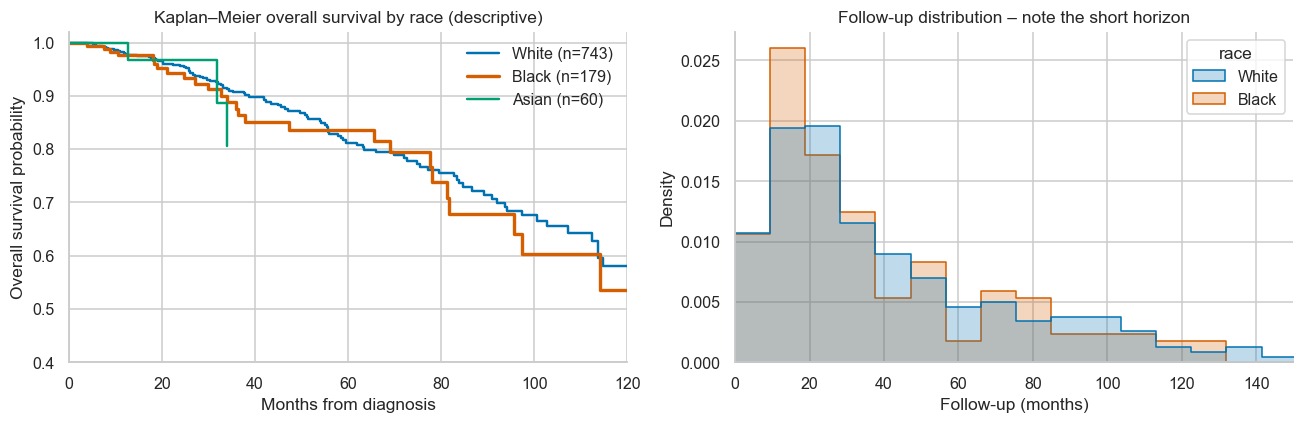

In [5]:
def kaplan_meier(t, e):
    t, e = np.asarray(t, float), np.asarray(e, int)
    xs, ys, S = [0.0], [1.0], 1.0
    for u in np.unique(t[e == 1]):
        n = (t >= u).sum(); d = ((t == u) & (e == 1)).sum()
        S *= 1 - d / n; xs.append(u); ys.append(S)
    return np.array(xs), np.array(ys)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for r in ["White", "Black", "Asian"]:
    s = clean[clean.race == r]
    xs, ys = kaplan_meier(s.os_months, s[TARGET])
    ax[0].step(xs, ys, where="post", color=RC[r], lw=2.2 if r == "Black" else 1.6, label=f"{r} (n={len(s)})")
ax[0].set(xlim=(0, 120), ylim=(0.4, 1.02), xlabel="Months from diagnosis", ylabel="Overall survival probability",
          title="Kaplan–Meier overall survival by race (descriptive)")
ax[0].legend(frameon=False)
sns.histplot(data=clean[clean.race.isin(["White", "Black"])], x="os_months", hue="race", palette=RC, bins=30,
             element="step", stat="density", common_norm=False, ax=ax[1])
ax[1].set(xlabel="Follow-up (months)", title="Follow-up distribution – note the short horizon"); ax[1].set_xlim(0, 150)
plt.tight_layout(); savefig("01_km_followup"); plt.show()

### 1.2 Missing-data audit — is “not recorded” itself predictive?

Tree models can learn from missingness. That is a feature when the missingness is clinically meaningful, and a **leak** when it reflects how the registry was filled in. For every candidate feature I compare the death rate among patients *with* vs *without* a recorded value (Fisher exact test), and check whether missingness differs by race.

In [6]:
from scipy.stats import fisher_exact
audit = []
action = {"n_stage": "NX → N0 (clinical default)", "m_stage": "MX → M0 (AJCC default)", "her2_pos": "not recorded → not positive",
          "menopause": "dropped (collinear with age)", "er_pos": "kept NaN (no signal)", "pr_pos": "kept NaN (no signal)",
          "t_stage": "kept NaN (n=3)", "histology": "kept NaN (n=2)"}
for c in ["t_stage", "n_stage", "m_stage", "er_pos", "pr_pos", "her2_pos", "menopause", "histology"]:
    m = clean[c].isna().values
    tab = [[int((y[m] == 1).sum()), int((y[m] == 0).sum())], [int((y[~m] == 1).sum()), int((y[~m] == 0).sum())]]
    audit.append({"feature": c, "n missing": int(m.sum()), "% missing": 100 * m.mean(), "death rate | missing": y[m].mean(), "death rate | recorded": y[~m].mean(),
                  "Fisher p": fisher_exact(tab)[1], "% missing (Black)": 100 * m[is_black].mean(), "% missing (White)": 100 * m[is_white].mean(), "action": action[c]})
audit = pd.DataFrame(audit).set_index("feature")
display(audit.style.format({"% missing": "{:.1f}", "death rate | missing": "{:.2f}", "death rate | recorded": "{:.2f}", "Fisher p": "{:.1e}", "% missing (Black)": "{:.1f}", "% missing (White)": "{:.1f}"})
        .background_gradient(subset=["Fisher p"], cmap="Reds_r", vmax=0.2))
mx = clean.assign(M=clean.m_stage.map({0.0: "M0", 1.0: "M1"}).fillna("MX")).groupby(["race", "M"]).agg(n=(TARGET, "size"), death_rate=(TARGET, "mean")).round(2).loc[["Black", "White"]]
print("M-stage by race — MX (not assessed) is far more common among Black patients and carries a *lower* death rate than M0:"); display(mx.T)

,n missing,% missing,death rate | missing,death rate | recorded,Fisher p,% missing (Black),% missing (White),action
feature,,,,,,,,
t_stage,3,0.3,0.33,0.15,3.8e-01,1.1,0.1,kept NaN (n=3)
n_stage,18,1.8,0.61,0.14,5.6e-06,3.4,1.6,NX → N0 (clinical default)
m_stage,156,15.9,0.09,0.16,3.5e-02,31.8,12.9,MX → M0 (AJCC default)
er_pos,52,5.3,0.19,0.14,3.1e-01,2.2,5.9,kept NaN (no signal)
pr_pos,55,5.6,0.16,0.14,6.9e-01,2.2,6.3,kept NaN (no signal)
her2_pos,139,14.2,0.33,0.12,1.2e-09,15.1,13.3,not recorded → not positive
menopause,109,11.1,0.37,0.12,5.9e-10,20.1,9.6,dropped (collinear with age)
histology,2,0.2,0.00,0.15,1.0e+00,0.0,0.3,kept NaN (n=2)


M-stage by race — MX (not assessed) is far more common among Black patients and carries a *lower* death rate than M0:


race         Black                White             
M               M0    M1     MX      M0     M1    MX
n           118.00  4.00  57.00  635.00  12.00  96.0
death_rate    0.19  0.75   0.07    0.14   0.92   0.1

**Interpretation.** Four features show outcome-associated missingness (HER2, menopause, N, and M — where MX patients have a *lower* death rate than M0 patients and are far more frequent among Black patients). Left as NaN, the model would use “M not assessed” as a protective factor for Black patients and “HER2 not recorded” as a risk factor — conclusions that are artefacts of documentation practice. This is exactly the kind of failure SHAP is good at *exposing* (§6.2 shows the naive model’s attributions), and the reason the audit comes before any modelling.

## 2. Train / validation / test split

As specified in §3.2.3: **60 % train** (learning + cross-validated tuning), **20 % validation** (early stopping), **20 % test** (touched once, at the end).
The split is **stratified on race × outcome** so that every partition contains Black patients *and* deaths among them — a plain random split on a cohort this size can easily leave a subgroup with zero events in the test set.

In [7]:
clean["split"] = split_labels(clean, seed=SEED).values
tr, va, te = [(clean.split == s).values for s in ["train", "val", "test"]]
X_tr, X_va, X_te = X[tr], X[va], X[te]
y_tr, y_va, y_te = y[tr], y[va], y[te]
display(pd.crosstab(clean.split, clean.race, margins=True).loc[["train", "val", "test", "All"]]
        .join(clean.groupby("split")[TARGET].sum().astype(int).rename("deaths")))
print("Black deaths per split:", clean[is_black].groupby("split")[TARGET].sum().astype(int).to_dict())

,Asian,Black,White,All,deaths
split,,,,,
train,36,107,445,588,86.0
val,12,36,149,197,28.0
test,12,36,149,197,29.0
All,60,179,743,982,NaN


Black deaths per split: {'test': 6, 'train': 17, 'val': 6}


**Consequence for the analysis:** the test set contains only ~6 deaths among Black patients, so *test-set* subgroup metrics are too noisy to conclude anything. I therefore report (a) the official hold-out test result for the whole cohort, as proposed, and (b) **repeated 5×5-fold cross-validated out-of-fold (OOF) predictions for all 982 patients**, which is where the subgroup comparisons are made.

## 3. Does XGBoost earn its place? Baseline comparison

The literature review (Table 2.2) positions XGBoost against simpler learners. I test that on *this* data with 5×3 repeated stratified CV on the training split (ROC-AUC and average precision; average precision is the more informative metric at ~15 % prevalence). The tuned XGBoost row is added in §4 once tuning is done (slightly optimistic, because the tuning folds overlap).

In [8]:
cv_base = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X_tr, strata[tr]))
models = {
    "Logistic regression": make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                                          LogisticRegression(max_iter=2000)),
    "Random forest": make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                    RandomForestClassifier(500, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
    "XGBoost (defaults)": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                                         colsample_bytree=0.8, eval_metric="logloss", random_state=SEED, n_jobs=1),
}
rows = []
for name, m in models.items():
    auc = cross_val_score(m, X_tr, y_tr, cv=cv_base, scoring="roc_auc")
    ap = cross_val_score(m, X_tr, y_tr, cv=cv_base, scoring="average_precision")
    rows.append({"model": name, "ROC-AUC": f"{auc.mean():.3f} ± {auc.std():.3f}", "Avg. precision": f"{ap.mean():.3f} ± {ap.std():.3f}"})
base_tbl = pd.DataFrame(rows).set_index("model")
display(base_tbl)

,ROC-AUC,Avg. precision
model,,
Logistic regression,0.589 ± 0.072,0.287 ± 0.064
Random forest,0.623 ± 0.066,0.286 ± 0.073
XGBoost (defaults),0.584 ± 0.047,0.264 ± 0.070


**Honest reading.** With ~86 training events, a regularised logistic regression, a random forest and default XGBoost are statistically indistinguishable (differences ≪ one fold-to-fold SD). XGBoost is therefore *not* selected here because it dominates — it does not — but because (i) it is the model the proposal studies, (ii) it handles missing values and non-linearities natively, and (iii) TreeSHAP gives **exact** attributions for it in polynomial time. The same SHAP workflow is available for the logistic model, which is a useful reference point for the reader.

## 4. XGBoost: hyper-parameter search, early stopping, recall-first threshold

* **Search:** 60-draw randomised search (note `min_child_weight` is searched on 0.05–3: XGBoost measures it in *hessian* units, which for a logistic loss at 15 % prevalence are ≈0.12 per patient, so the default range of 1–10 would forbid any split on a rare-but-decisive group such as the 16 M1 patients), 5×2 repeated stratified CV **on the training split only**, scoring ROC-AUC. The grid leans towards shallow, heavily regularised trees (depth 2–4, L1/L2, γ) because with ~150 events deep trees just memorise.
* **Early stopping** on the validation split (logloss) guards against over-fitting; train-vs-validation loss is plotted.
* **Class imbalance:** I do **not** re-weight classes. Re-weighting distorts the probabilities (they stop meaning “risk”), which matters for the dashboard and for calibration analysis. Instead, the proposal’s *recall-first* objective is met by choosing the **decision threshold** that gives ≥ 80 % recall on out-of-fold training predictions.

In [9]:
TARGET_RECALL = 0.80
cv_search = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED).split(X_tr, strata[tr]))
param_dist = dict(
    n_estimators=randint(60, 500), learning_rate=loguniform(0.01, 0.2), max_depth=randint(2, 5),
    min_child_weight=loguniform(0.05, 3), subsample=uniform(0.6, 0.4), colsample_bytree=uniform(0.5, 0.5),
    reg_lambda=loguniform(0.5, 20), reg_alpha=loguniform(1e-3, 5), gamma=uniform(0, 2))
search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=1),
    param_dist, n_iter=60, scoring="roc_auc", cv=cv_search, random_state=SEED, n_jobs=-1, refit=False)
t0 = time.time(); search.fit(X_tr, y_tr)
best = {k: (float(v) if isinstance(v, (np.floating, float)) else int(v)) for k, v in search.best_params_.items()}
print(f"search finished in {time.time()-t0:.0f}s | best CV ROC-AUC = {search.best_score_:.3f}")
display(pd.Series(best, name="best hyper-parameters").to_frame().T)

search finished in 32s | best CV ROC-AUC = 0.629


,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample
best hyper-parameters,0.705519,0.066101,0.028116,2.0,0.133336,189.0,0.092026,2.608228,0.821157


early stopping on the validation split kept 129 trees (cap 1000)


decision threshold = 0.101  (largest value achieving ≥80% out-of-fold recall on the training split)


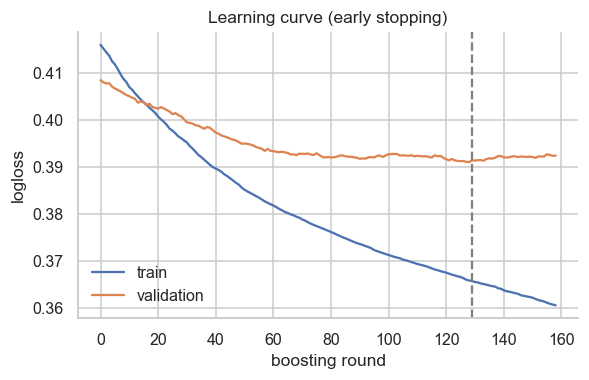

,ROC-AUC,Avg. precision
model,,
Logistic regression,0.589 ± 0.072,0.287 ± 0.064
Random forest,0.623 ± 0.066,0.286 ± 0.073
XGBoost (defaults),0.584 ± 0.047,0.264 ± 0.070
"XGBoost (tuned, optimistic)",0.620 ± 0.059,0.333 ± 0.085


In [10]:
# --- final model: early stopping on the validation split --------------------------------------
final = XGBClassifier(**{**best, "n_estimators": 1000}, eval_metric="logloss", tree_method="hist", early_stopping_rounds=30,
                      random_state=SEED, n_jobs=1)          # tuned learning rate etc.; the VALIDATION set decides how many trees
final.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_va, y_va)], verbose=False)
BEST_N = int(final.best_iteration) + 1
print(f"early stopping on the validation split kept {BEST_N} trees (cap 1000)")

def make_model(n=None, features=None, seed=SEED, **over):
    p = {**best, "n_estimators": n or BEST_N, **over}
    return XGBClassifier(**p, eval_metric="logloss", tree_method="hist", random_state=seed, n_jobs=1)

# --- decision threshold from OUT-OF-FOLD training predictions (validation/test never used) ------
oof_tr = np.zeros(tr.sum())
for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tr, strata[tr]):
    oof_tr[b] = make_model().fit(X_tr.iloc[a], y_tr[a]).predict_proba(X_tr.iloc[b])[:, 1]
fpr_, tpr_, thr_ = roc_curve(y_tr, oof_tr)
THR = float(thr_[np.argmax(tpr_ >= TARGET_RECALL)])
print(f"decision threshold = {THR:.3f}  (largest value achieving ≥{TARGET_RECALL:.0%} out-of-fold recall on the training split)")

ev = final.evals_result()
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(ev["validation_0"]["logloss"], label="train"); ax.plot(ev["validation_1"]["logloss"], label="validation")
ax.axvline(BEST_N, ls="--", c="grey"); ax.set(xlabel="boosting round", ylabel="logloss", title="Learning curve (early stopping)")
ax.legend(frameon=False); plt.tight_layout(); savefig("02_learning_curve"); plt.show()

# tuned XGBoost on the same folds as the baselines (optimistic: folds overlap with the tuning folds)
tuned = make_model()
auc_t = cross_val_score(tuned, X_tr, y_tr, cv=cv_base, scoring="roc_auc"); ap_t = cross_val_score(tuned, X_tr, y_tr, cv=cv_base, scoring="average_precision")
base_tbl.loc["XGBoost (tuned, optimistic)"] = [f"{auc_t.mean():.3f} ± {auc_t.std():.3f}", f"{ap_t.mean():.3f} ± {ap_t.std():.3f}"]
display(base_tbl)

## 5. Hold-out test performance (Objective 2)

In [11]:
def metrics(y_true, p, thr):
    y_true = np.asarray(y_true); p = np.asarray(p); yh = p >= thr
    tp = int(((yh == 1) & (y_true == 1)).sum()); fn = int(((yh == 0) & (y_true == 1)).sum())
    fp = int(((yh == 1) & (y_true == 0)).sum()); tn = int(((yh == 0) & (y_true == 0)).sum())
    two = 0 < y_true.sum() < len(y_true)
    return {"n": len(y_true), "deaths": int(y_true.sum()),
            "AUC": roc_auc_score(y_true, p) if two else np.nan,
            "AvgPrecision": average_precision_score(y_true, p) if two else np.nan,
            "Accuracy": (tp + tn) / len(y_true),
            "Recall": tp / max(tp + fn, 1), "Specificity": tn / max(tn + fp, 1),
            "Precision": tp / max(tp + fp, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "FNR": fn / max(tp + fn, 1), "FPR": fp / max(fp + tn, 1),
            "Brier": brier_score_loss(y_true, p), "MeanPred": p.mean(), "ObsRate": y_true.mean()}

def boot(y_true, p, thr, B=1000, seed=0):
    """Stratified (by outcome) non-parametric bootstrap of all metrics."""
    r = np.random.default_rng(seed); y_true = np.asarray(y_true); p = np.asarray(p)
    i1, i0 = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
    out = []
    for _ in range(B):
        i = np.concatenate([r.choice(i1, len(i1)), r.choice(i0, len(i0))])
        out.append(metrics(y_true[i], p[i], thr))
    return pd.DataFrame(out)

def fmt(point, bs, key, d=2):
    lo, hi = np.nanpercentile(bs[key], [2.5, 97.5])
    return f"{point[key]:.{d}f} ({lo:.{d}f}–{hi:.{d}f})"

p_te = final.predict_proba(X_te)[:, 1]
m_te, b_te = metrics(y_te, p_te, THR), boot(y_te, p_te, THR)
keys = ["AUC", "AvgPrecision", "Accuracy", "Precision", "Recall", "Specificity", "F1", "Brier"]
display(pd.Series({k: fmt(m_te, b_te, k) for k in keys}, name=f"Test set (n={len(y_te)}, deaths={y_te.sum()}) – point (95% CI)").to_frame())

,"Test set (n=197, deaths=29) – point (95% CI)"
AUC,0.74 (0.63–0.84)
AvgPrecision,0.40 (0.28–0.56)
Accuracy,0.35 (0.29–0.41)
Precision,0.18 (0.16–0.20)
Recall,0.93 (0.83–1.00)
Specificity,0.25 (0.19–0.32)
F1,0.30 (0.26–0.33)
Brier,0.11 (0.10–0.12)


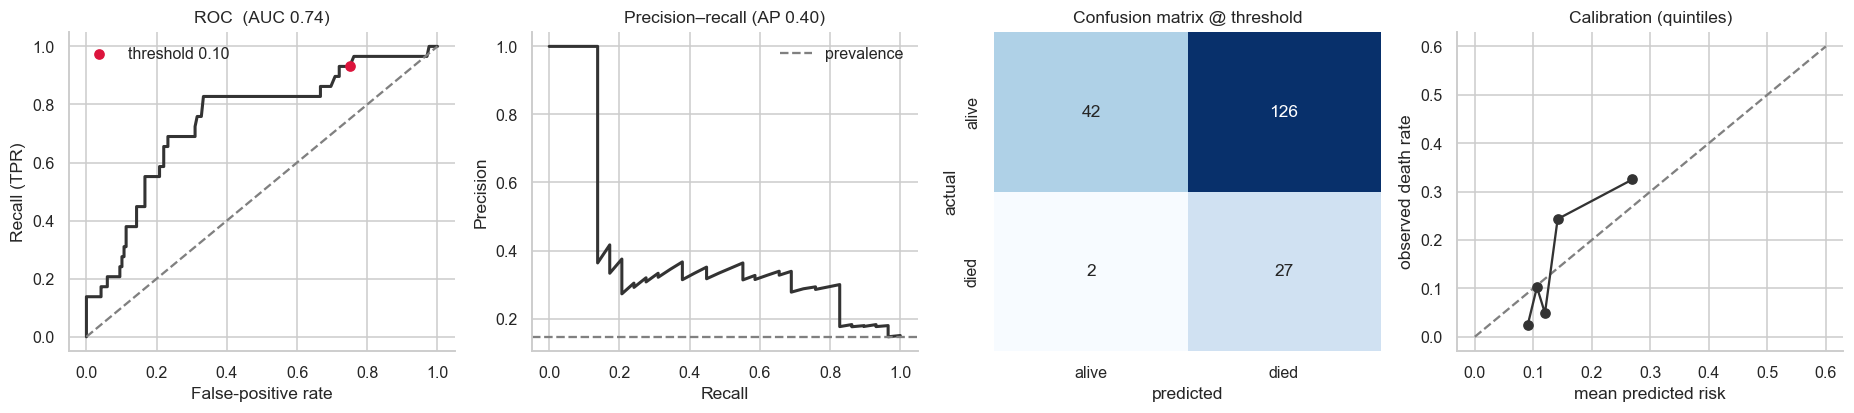

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0].plot(fpr, tpr, lw=2, color="#333"); ax[0].plot([0, 1], [0, 1], "--", c="grey")
ax[0].scatter([m_te["FPR"]], [m_te["Recall"]], c="crimson", zorder=3, label=f"threshold {THR:.2f}")
ax[0].set(xlabel="False-positive rate", ylabel="Recall (TPR)", title=f"ROC  (AUC {m_te['AUC']:.2f})"); ax[0].legend(frameon=False)
pr_, rc_, _ = precision_recall_curve(y_te, p_te)
ax[1].plot(rc_, pr_, lw=2, color="#333"); ax[1].axhline(y_te.mean(), ls="--", c="grey", label="prevalence")
ax[1].set(xlabel="Recall", ylabel="Precision", title=f"Precision–recall (AP {m_te['AvgPrecision']:.2f})"); ax[1].legend(frameon=False)
cm = confusion_matrix(y_te, p_te >= THR)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[2], xticklabels=["alive", "died"], yticklabels=["alive", "died"])
ax[2].set(xlabel="predicted", ylabel="actual", title="Confusion matrix @ threshold")
# reliability
q = pd.qcut(p_te, 5, duplicates="drop")
cal = pd.DataFrame({"p": p_te, "y": y_te}).groupby(q, observed=True).mean()
ax[3].plot([0, .6], [0, .6], "--", c="grey"); ax[3].plot(cal.p, cal.y, "o-", c="#333")
ax[3].set(xlabel="mean predicted risk", ylabel="observed death rate", title="Calibration (quintiles)")
plt.tight_layout(); savefig("03_test_performance"); plt.show()

## 6. Repeated-CV out-of-fold predictions for *every* patient, and performance **by race**

Each patient is scored 5 times (5 repeats of 5-fold CV, each time by a model that **never saw that patient**) and the predictions are averaged. This gives an honest, leakage-free risk estimate for all 982 patients and makes subgroup comparison feasible. (Nested properly: hyper-parameters were chosen on the training split only, but the cohort is then re-used for out-of-fold *estimation*, which is standard for small cohorts; the strict hold-out result is §5.)

In [13]:
def oof_predict(feats, Xm=None, repeats=5, folds=5, seed=SEED):
    Xm = X if Xm is None else Xm
    preds = np.zeros((repeats, len(Xm)))
    for r in range(repeats):
        for a, b in StratifiedKFold(folds, shuffle=True, random_state=seed + r).split(Xm, strata):
            m = make_model(seed=seed + r).fit(Xm.iloc[a][feats], y[a])
            preds[r, b] = m.predict_proba(Xm.iloc[b][feats])[:, 1]
    return preds.mean(0)

clean["risk_oof"] = oof_predict(FEATURES)
clean["risk_oof_norace"] = oof_predict(FEATURES_NO_RACE)
print("overall OOF AUC:", round(roc_auc_score(y, clean.risk_oof), 3), "| race-blind twin:", round(roc_auc_score(y, clean.risk_oof_norace), 3))

# the OOF-based threshold (same target recall, now on all patients) used for fairness analysis
fpr_o, tpr_o, thr_o = roc_curve(y, clean.risk_oof)
THR_OOF = float(thr_o[np.argmax(tpr_o >= TARGET_RECALL)])
print(f"OOF threshold for ≥{TARGET_RECALL:.0%} recall: {THR_OOF:.3f}  (training-split threshold was {THR:.3f})")

rows = []
for grp, mask in [("All", np.ones(len(y), bool)), ("White", is_white), ("Black", is_black), ("Asian", (clean.race == "Asian").values)]:
    m = metrics(y[mask], clean.risk_oof[mask], THR_OOF); b = boot(y[mask], clean.risk_oof[mask], THR_OOF, B=600, seed=1)
    rows.append({"Group": grp, "n": m["n"], "Deaths": m["deaths"], **{k: fmt(m, b, k) for k in ["AUC", "AvgPrecision", "Recall", "Specificity", "Precision", "FNR", "Brier"]},
                 "Mean pred. / observed": f"{m['MeanPred']:.3f} / {m['ObsRate']:.3f}"})
perf_by_race = pd.DataFrame(rows).set_index("Group")
display(perf_by_race)
print("Asian row (3 deaths) is reported for completeness only; it supports no inference.")

overall OOF AUC: 0.654 | race-blind twin: 0.648
OOF threshold for ≥80% recall: 0.105  (training-split threshold was 0.101)


,n,Deaths,AUC,AvgPrecision,Recall,Specificity,Precision,FNR,Brier,Mean pred. / observed
Group,,,,,,,,,,
All,982,143,0.65 (0.60–0.70),0.33 (0.26–0.40),0.80 (0.74–0.87),0.33 (0.30–0.36),0.17 (0.16–0.18),0.20 (0.13–0.26),0.11 (0.11–0.12),0.143 / 0.146
White,743,111,0.66 (0.60–0.71),0.35 (0.28–0.43),0.80 (0.72–0.86),0.33 (0.30–0.37),0.17 (0.16–0.19),0.20 (0.14–0.28),0.12 (0.11–0.12),0.144 / 0.149
Black,179,29,0.61 (0.48–0.73),0.29 (0.19–0.46),0.83 (0.69–0.97),0.23 (0.17–0.29),0.17 (0.14–0.20),0.17 (0.03–0.31),0.13 (0.12–0.14),0.151 / 0.162
Asian,60,3,0.74 (0.42–0.96),0.19 (0.08–0.60),0.67 (0.00–1.00),0.60 (0.47–0.72),0.08 (0.00–0.14),0.33 (0.00–1.00),0.05 (0.05–0.05),0.111 / 0.050


Asian row (3 deaths) is reported for completeness only; it supports no inference.


### 6.1 Group fairness: equal opportunity, equalised odds, calibration

A single global threshold can produce different **false-negative rates** across groups even when AUC is similar. Equal opportunity (equal recall) is the property the proposal cares about most. I use **paired bootstrap** (Black and White resampled independently) to put a CI on the gaps, then examine **calibration by race** (calibration-in-the-large and slope).

,Black,White,Gap (Black − White),95% CI of gap
Recall / TPR (equal opportunity),0.828,0.802,0.026,"(-0.14, +0.17)"
False-positive rate,0.773,0.668,0.106,"(+0.03, +0.18)"
Precision (PPV),0.171,0.174,-0.003,"(-0.03, +0.03)"
AUC,0.609,0.655,-0.046,"(-0.19, +0.08)"


,Calibration slope (ideal 1),Mean predicted,Observed rate
White,1.28 (0.97–1.63),0.144,0.149
Black,0.90 (0.07–1.64),0.151,0.162


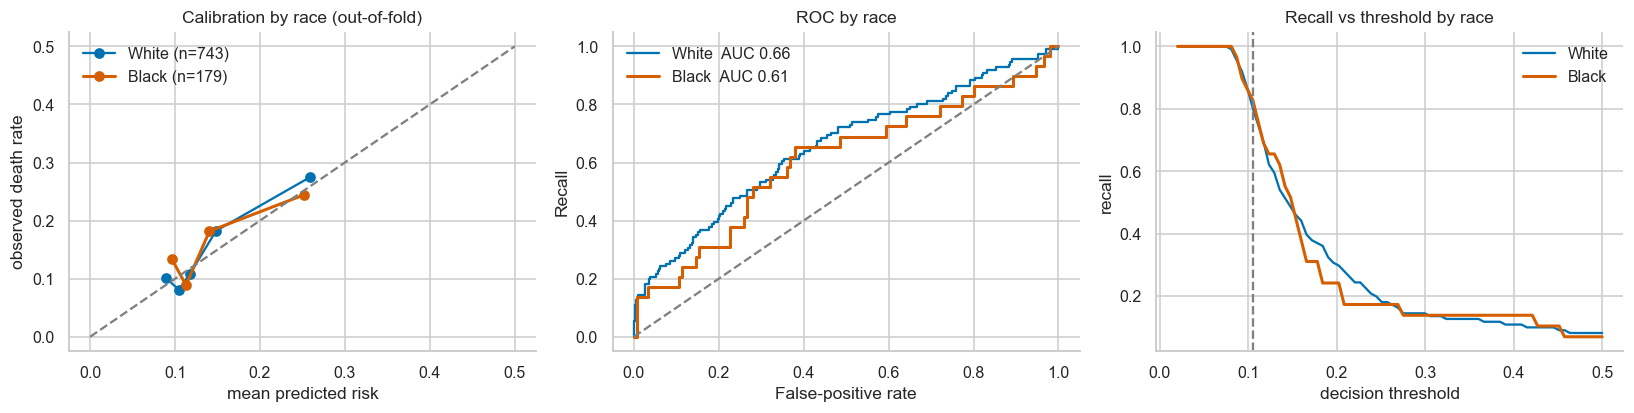

**Operating-point note.** At the single global threshold (0.105) recall is **83%** for Black and **80%** for White patients, with specificity 23% / 33%. Group-specific thresholds that hit exactly 80% recall within each group would be 0.105 (Black; specificity 23%) and 0.105 (White; specificity 33%). With only 29 Black events the Black-specific threshold itself is very uncertain, so this is shown as a sensitivity check, not a recommendation.

In [14]:
def gap_ci(B=1000, thr=THR_OOF, seed=3):
    r = np.random.default_rng(seed); out = []
    pb, yb = clean.risk_oof.values[is_black], y[is_black]; pw, yw = clean.risk_oof.values[is_white], y[is_white]
    def res(yv, pv):
        i1, i0 = np.where(yv == 1)[0], np.where(yv == 0)[0]
        i = np.concatenate([r.choice(i1, len(i1)), r.choice(i0, len(i0))]); return metrics(yv[i], pv[i], thr)
    for _ in range(B):
        mb, mw = res(yb, pb), res(yw, pw)
        out.append({k: mb[k] - mw[k] for k in ["Recall", "FPR", "Precision", "AUC", "Brier"]} | {"MeanPred_minus_Obs_B": mb["MeanPred"] - mb["ObsRate"], "MeanPred_minus_Obs_W": mw["MeanPred"] - mw["ObsRate"]})
    return pd.DataFrame(out)

mB, mW = metrics(y[is_black], clean.risk_oof[is_black], THR_OOF), metrics(y[is_white], clean.risk_oof[is_white], THR_OOF)
g = gap_ci()
fair = pd.DataFrame({
    "Black": [mB[k] for k in ["Recall", "FPR", "Precision", "AUC"]],
    "White": [mW[k] for k in ["Recall", "FPR", "Precision", "AUC"]],
    "Gap (Black − White)": [mB[k] - mW[k] for k in ["Recall", "FPR", "Precision", "AUC"]],
    "95% CI of gap": [f"({np.percentile(g[k],2.5):+.2f}, {np.percentile(g[k],97.5):+.2f})" for k in ["Recall", "FPR", "Precision", "AUC"]],
}, index=["Recall / TPR (equal opportunity)", "False-positive rate", "Precision (PPV)", "AUC"]).round(3)
display(fair)

def calib_stats(p, yv, B=500, seed=0):
    r = np.random.default_rng(seed); lg = lambda q: np.log(np.clip(q, 1e-4, 1 - 1e-4) / (1 - np.clip(q, 1e-4, 1 - 1e-4)))
    def fit(pv, yy):
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(lg(pv).reshape(-1, 1), yy); return lr.coef_[0, 0], lr.intercept_[0]
    s, i = fit(p, yv); bs = []
    for _ in range(B):
        k = r.integers(0, len(p), len(p))
        if yv[k].sum() > 1: bs.append(fit(p[k], yv[k]))
    bs = np.array(bs); return s, np.percentile(bs[:, 0], [2.5, 97.5]), i
cal_rows = {}
for grp, mask in [("White", is_white), ("Black", is_black)]:
    s, ci, i = calib_stats(clean.risk_oof.values[mask], y[mask])
    cal_rows[grp] = {"Calibration slope (ideal 1)": f"{s:.2f} ({ci[0]:.2f}–{ci[1]:.2f})", "Mean predicted": round(clean.risk_oof.values[mask].mean(), 3), "Observed rate": round(y[mask].mean(), 3)}
display(pd.DataFrame(cal_rows).T)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
for r_, mask in [("White", is_white), ("Black", is_black)]:
    pv, yv = clean.risk_oof.values[mask], y[mask]
    nb_ = 5 if r_ == "White" else 4
    q = pd.qcut(pv, nb_, duplicates="drop"); c = pd.DataFrame({"p": pv, "y": yv}).groupby(q, observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    ax[0].plot(c.p, c.y, "o-", color=RC[r_], label=f"{r_} (n={mask.sum()})", lw=2 if r_ == "Black" else 1.5)
    fp_, tp_, _ = roc_curve(yv, pv); ax[1].plot(fp_, tp_, color=RC[r_], lw=2 if r_ == "Black" else 1.5, label=f"{r_}  AUC {roc_auc_score(yv, pv):.2f}")
ax[0].plot([0, .5], [0, .5], "--", c="grey"); ax[0].set(xlabel="mean predicted risk", ylabel="observed death rate", title="Calibration by race (out-of-fold)"); ax[0].legend(frameon=False)
ax[1].plot([0, 1], [0, 1], "--", c="grey"); ax[1].set(xlabel="False-positive rate", ylabel="Recall", title="ROC by race"); ax[1].legend(frameon=False)
# recall as a function of threshold, per race
ths = np.linspace(0.02, 0.5, 80)
for r_, mask in [("White", is_white), ("Black", is_black)]:
    ax[2].plot(ths, [((clean.risk_oof.values[mask] >= t) & (y[mask] == 1)).sum() / y[mask].sum() for t in ths], color=RC[r_], label=r_, lw=2 if r_ == "Black" else 1.5)
ax[2].axvline(THR_OOF, ls="--", c="grey"); ax[2].set(xlabel="decision threshold", ylabel="recall", title="Recall vs threshold by race"); ax[2].legend(frameon=False)
plt.tight_layout(); savefig("04_fairness_by_race"); plt.show()

# group-specific operating point: what threshold would give exactly the target recall within each group?
def op_point(mask):
    f_, t_, th_ = roc_curve(y[mask], clean.risk_oof.values[mask]); k = np.argmax(t_ >= TARGET_RECALL); return float(th_[k]), 1 - f_[k]
thr_b, sp_b_own = op_point(is_black); thr_w, sp_w_own = op_point(is_white)
display(Markdown(f"**Operating-point note.** At the single global threshold ({THR_OOF:.3f}) recall is **{mB['Recall']:.0%}** for Black and **{mW['Recall']:.0%}** for White patients, with specificity {mB['Specificity']:.0%} / {mW['Specificity']:.0%}. "
                 f"Group-specific thresholds that hit exactly {TARGET_RECALL:.0%} recall within each group would be {thr_b:.3f} (Black; specificity {sp_b_own:.0%}) and {thr_w:.3f} (White; specificity {sp_w_own:.0%}). "
                 f"With only {int(y[is_black].sum())} Black events the Black-specific threshold itself is very uncertain, so this is shown as a sensitivity check, not a recommendation."))

### 6.2 Ablation: what did the missing-data protection cost (and what was it hiding)?

Same hyper-parameters, same CV folds, but the *naive* encoding (NaN kept for HER2 / N / M, menopausal status included).

In [15]:
X_naive = encode(clean, naive=True)
clean["risk_oof_naive"] = oof_predict(FEATURES_NAIVE, Xm=X_naive)
sh_n = np.abs(shap.TreeExplainer(make_model().fit(X_naive, y)).shap_values(X_naive)).mean(0); sh_n = pd.Series(sh_n / sh_n.sum(), index=FEATURES_NAIVE)
abl = pd.DataFrame({"naive (leaky missingness)": [roc_auc_score(y, clean.risk_oof_naive), roc_auc_score(y[is_black], clean.risk_oof_naive[is_black]), roc_auc_score(y[is_white], clean.risk_oof_naive[is_white])],
                    "protected (final)": [roc_auc_score(y, clean.risk_oof), roc_auc_score(y[is_black], clean.risk_oof[is_black]), roc_auc_score(y[is_white], clean.risk_oof[is_white])]},
                   index=["AUC all", "AUC Black", "AUC White"]).round(3)
display(abl)
print("Naive model — share of total attribution on the features with informative missingness:")
display((100 * sh_n[["menopause", "her2_pos", "n_stage", "m_stage"]]).rename(index=LABELS).round(1).to_frame("% of mean|SHAP|"))

,naive (leaky missingness),protected (final)
AUC all,0.765,0.654
AUC Black,0.750,0.609
AUC White,0.767,0.655


Naive model — share of total attribution on the features with informative missingness:


,% of mean|SHAP|
Menopausal status,19.5
HER2 positive,18.1
Nodal status (N),18.4
Distant metastasis (M1),6.9


Any AUC the naive model gains over the protected one is, at least in part, the registry artefact — apparent accuracy that would not transfer to another hospital. The protected model is the honest one, and the attribution table shows how much of the naive model’s reasoning rested on those columns.

## 7. SHAP: global and local explanations (Objective 3)

`TreeExplainer` computes **exact** Shapley values for tree ensembles in polynomial time. For a binary XGBoost model the explanation is on the **log-odds** scale:

$$\mathrm{logit}\,\hat p(x) \;=\; \phi_0 + \sum_{j}\phi_j(x)$$

where φ₀ is the cohort-average log-odds and φⱼ(x) is feature *j*’s push for patient *x* (positive = towards higher mortality risk; exp(φⱼ) is the multiplicative change in the *odds*). I verify this additivity numerically before trusting any plot.

In [16]:
explainer = shap.TreeExplainer(final)
sv = explainer(X)                                    # shap.Explanation, log-odds units
names = [LABELS[f] for f in FEATURES]
sv_d = shap.Explanation(values=sv.values, base_values=sv.base_values, data=X.values, feature_names=names)
p_final = final.predict_proba(X)[:, 1]
recon = 1 / (1 + np.exp(-(sv.base_values + sv.values.sum(1))))
print(f"additivity check  max|sigmoid(φ0+Σφ) − p̂| = {np.abs(recon - p_final).max():.2e}   (≈0 ⇒ explanations are exact)")
print(f"base value φ0 = {sv.base_values[0]:+.3f} log-odds  → baseline risk {1/(1+np.exp(-sv.base_values[0])):.1%}")
clean["risk_final"] = p_final
SHAP = pd.DataFrame(sv.values, columns=FEATURES, index=clean.index)

additivity check  max|sigmoid(φ0+Σφ) − p̂| = 1.79e-07   (≈0 ⇒ explanations are exact)
base value φ0 = -1.778 log-odds  → baseline risk 14.5%


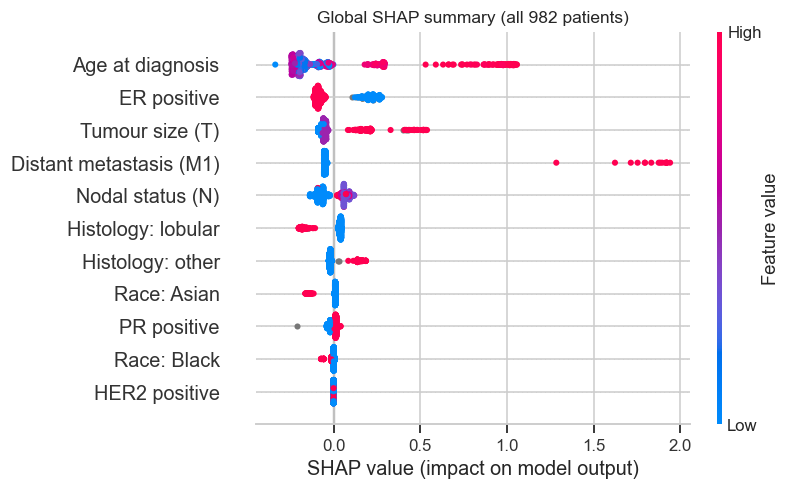

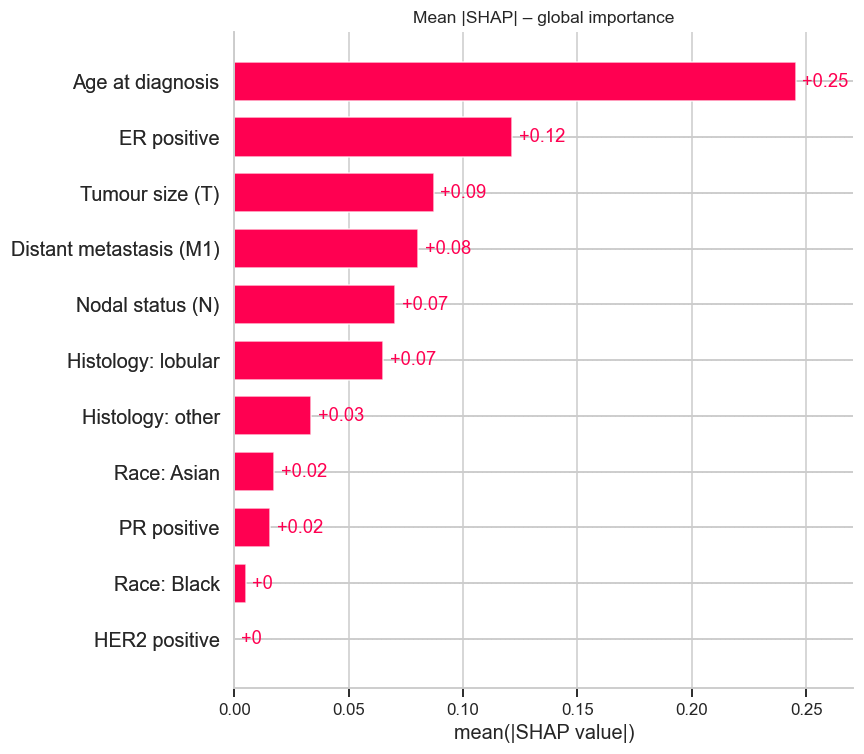

In [17]:
plt.figure(figsize=(7.5, 4.6)); shap.plots.beeswarm(sv_d, max_display=12, show=False, plot_size=None)
plt.title("Global SHAP summary (all 982 patients)"); plt.tight_layout(); savefig("05_shap_beeswarm_all"); plt.show()
plt.figure(figsize=(6.5, 4)); shap.plots.bar(sv_d, max_display=12, show=False)
plt.title("Mean |SHAP| – global importance"); plt.tight_layout(); savefig("06_shap_bar_all"); plt.show()

### 7.1 Do different importance measures agree? (consistency check)

SHAP is not the only importance measure. If gain-based importance, permutation importance and SHAP disagree wildly, the explanation is fragile. I compare the three rankings (permutation importance is computed on the **held-out test split** with 50 repeats).

In [18]:
imp = pd.DataFrame({
    "SHAP mean|φ|": np.abs(SHAP.values).mean(0),
    "XGB gain": pd.Series(final.get_booster().get_score(importance_type="gain")).reindex(FEATURES).fillna(0).values,
}, index=FEATURES)
pi = permutation_importance(final, X_te, y_te, scoring="roc_auc", n_repeats=50, random_state=SEED)
imp["Permutation ΔAUC (test)"] = pi.importances_mean
imp_rank = imp.rank(ascending=False)
rho = imp.corr(method="spearman")
shares = pd.DataFrame({"SHAP share": imp["SHAP mean|φ|"] / imp["SHAP mean|φ|"].sum(), "Gain share": imp["XGB gain"] / imp["XGB gain"].sum(),
                       "Permutation ΔAUC (test, ±SD)": [f"{m:+.3f} ± {s_:.3f}" for m, s_ in zip(pi.importances_mean, pi.importances_std)]}, index=FEATURES)
display(shares.rename(index=LABELS).sort_values("SHAP share", ascending=False).round(3))
print("Permutation importance on a 197-patient test set with 29 events is noisy (SD of the order of its mean): a coarse cross-check, not a ranking.")
print("Spearman rank agreement between measures:"); display(rho.round(2))

,SHAP share,Gain share,"Permutation ΔAUC (test, ±SD)"
Age at diagnosis,0.331,0.121,+0.108 ± 0.038
ER positive,0.164,0.095,+0.041 ± 0.025
Tumour size (T),0.118,0.110,+0.033 ± 0.015
Distant metastasis (M1),0.108,0.181,+0.056 ± 0.016
Nodal status (N),0.095,0.086,+0.010 ± 0.009
Histology: lobular,0.088,0.093,+0.003 ± 0.014
Histology: other,0.045,0.091,-0.003 ± 0.008
Race: Asian,0.024,0.071,+0.006 ± 0.006
PR positive,0.021,0.046,-0.001 ± 0.004
Race: Black,0.007,0.070,+0.001 ± 0.003


Permutation importance on a 197-patient test set with 29 events is noisy (SD of the order of its mean): a coarse cross-check, not a ranking.
Spearman rank agreement between measures:


,SHAP mean|φ|,XGB gain,Permutation ΔAUC (test)
SHAP mean|φ|,1.00,0.90,0.84
XGB gain,0.90,1.00,0.79
Permutation ΔAUC (test),0.84,0.79,1.00


### 7.2 Dependence plots – the *shape* of each effect

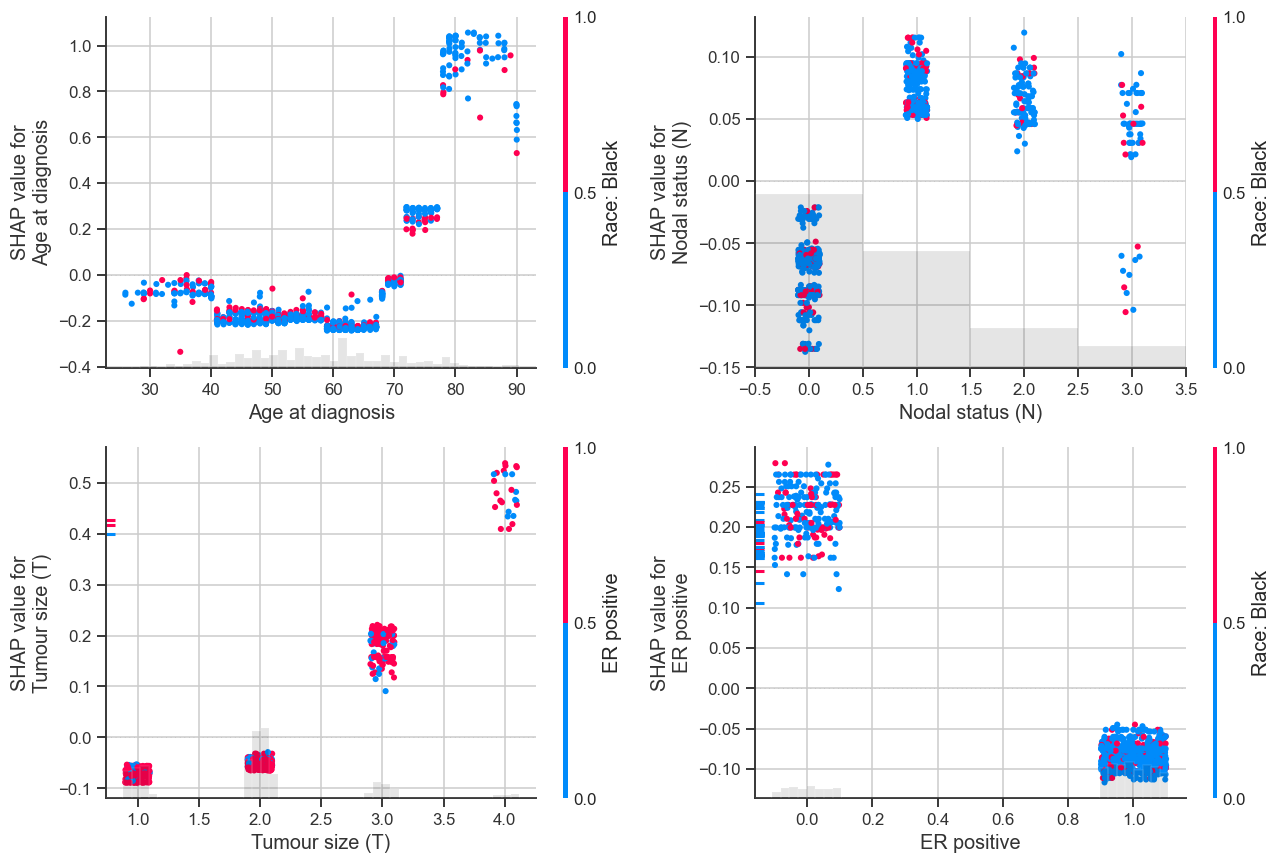

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax_, (f, c) in zip(axes.ravel(), [("Age at diagnosis", "Race: Black"), ("Nodal status (N)", "Race: Black"),
                                      ("Tumour size (T)", "ER positive"), ("ER positive", "Race: Black")]):
    shap.plots.scatter(sv_d[:, f], color=sv_d[:, c], ax=ax_, show=False)
plt.tight_layout(); savefig("07_dependence"); plt.show()

### 7.3 Interactions (SHAP interaction values)
Off-diagonal cells show how much two features *jointly* move predictions beyond their separate effects.

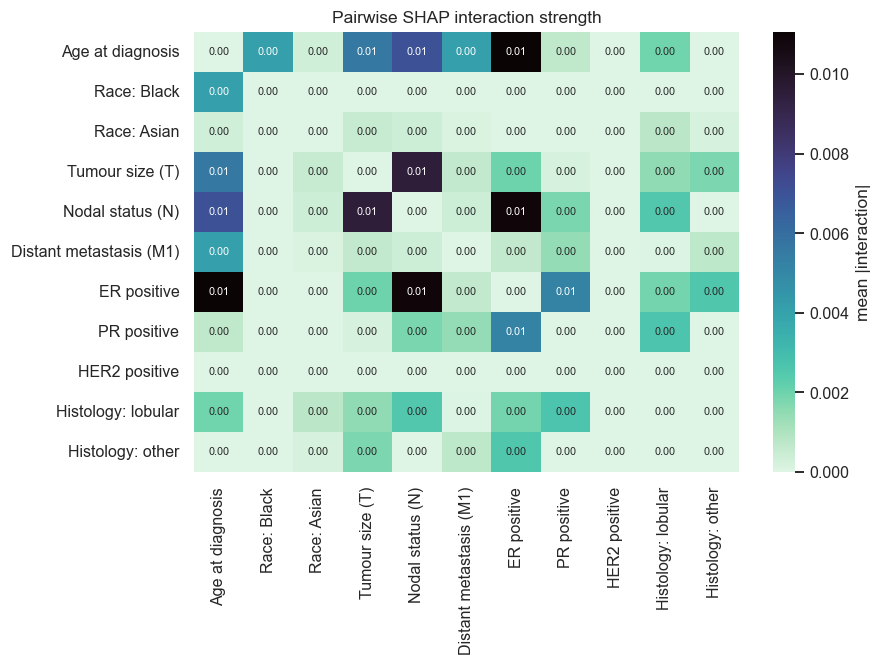

In [20]:
inter = explainer.shap_interaction_values(X)                    # (n, p, p)
M = np.abs(inter).mean(0); np.fill_diagonal(M, 0)
fig, ax = plt.subplots(figsize=(8.2, 6.2))
sns.heatmap(pd.DataFrame(M, index=names, columns=names), cmap="mako_r", annot=True, fmt=".02f", cbar_kws={"label": "mean |interaction|"}, ax=ax, annot_kws={"size": 7})
ax.set_title("Pairwise SHAP interaction strength"); plt.tight_layout(); savefig("08_interactions"); plt.show()

### 7.4 Local explanations – three illustrative Black patients
Chosen from the out-of-fold predictions: a correctly flagged death, a **missed death (false negative)**, and a correctly low-risk survivor.

True positive (died, flagged): TCGA-UU-A93S | age 63 | T4 N3 | ER 0.0 | OOF risk 63.9% | final-model risk 65.8%


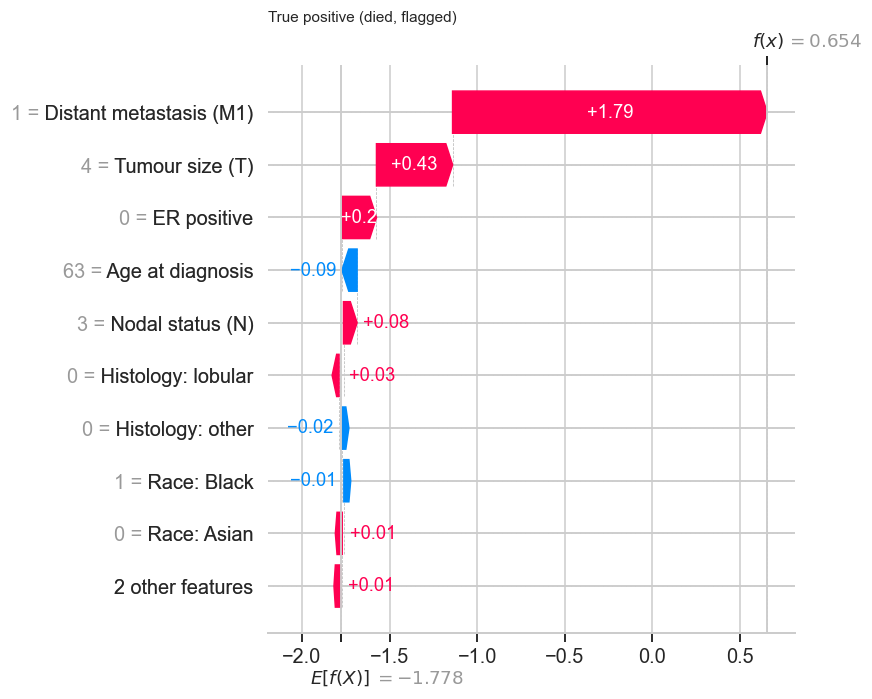

False negative (died, NOT flagged): TCGA-B6-A0RH | age 51 | T2 N0 | ER 1.0 | OOF risk 8.6% | final-model risk 10.2%


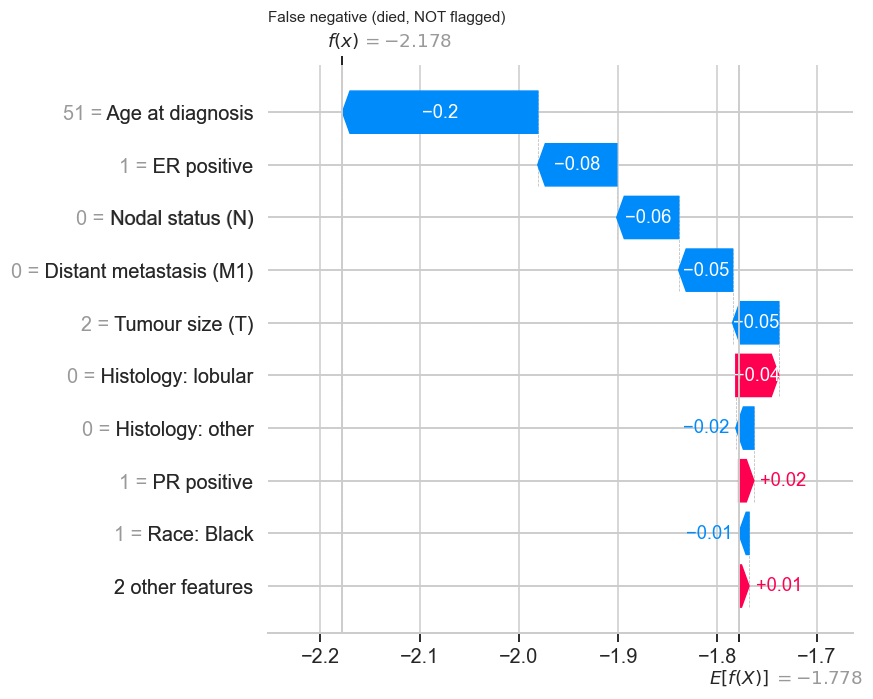

True negative (alive, low risk): TCGA-E2-A15L | age 65 | T2 N0 | ER 1.0 | OOF risk 8.3% | final-model risk 8.0%


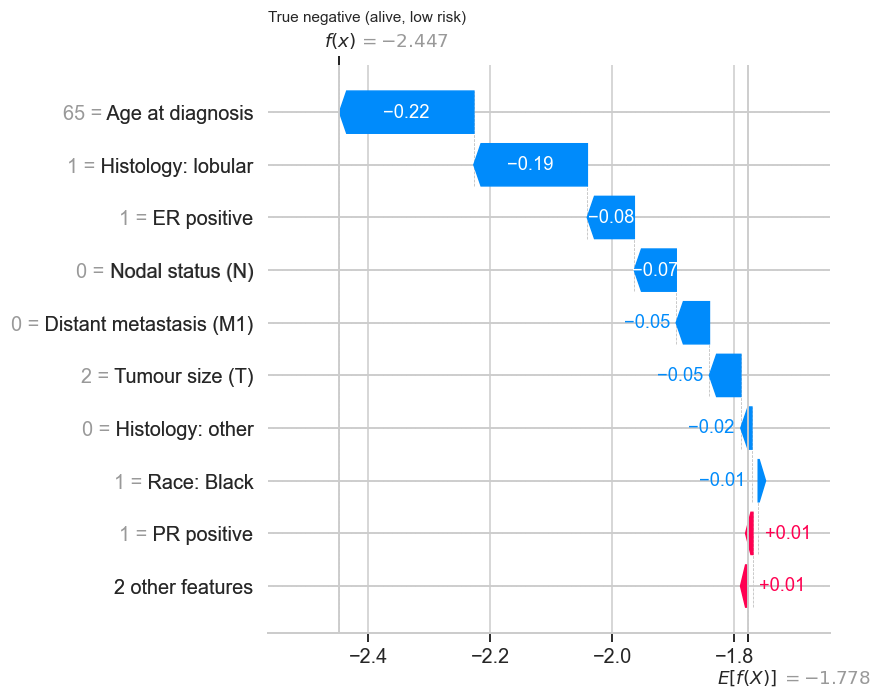

In [21]:
bl = clean[is_black].copy()
i_tp = bl[(bl[TARGET] == 1) & (bl.risk_oof >= THR_OOF)].risk_oof.idxmax()
i_fn = bl[(bl[TARGET] == 1) & (bl.risk_oof < THR_OOF)].risk_oof.idxmin()
i_tn = bl[(bl[TARGET] == 0) & (bl.risk_oof < THR_OOF)].risk_oof.idxmin()
for tag, i in [("True positive (died, flagged)", i_tp), ("False negative (died, NOT flagged)", i_fn), ("True negative (alive, low risk)", i_tn)]:
    row = clean.loc[i]
    print(f"{tag}: {row.patient_id} | age {row.age:.0f} | T{row.t_stage:.0f} N{row.n_stage:.0f} | ER {row.er_pos} | OOF risk {row.risk_oof:.1%} | final-model risk {row.risk_final:.1%}")
    plt.figure(); shap.plots.waterfall(sv_d[i], max_display=10, show=False); plt.title(tag, loc="left", fontsize=10); plt.tight_layout()
    savefig(f"09_waterfall_{tag.split()[0].lower()}_{tag.split()[1].lower()}"); plt.show()

## 8. How do features affect predictions for Black patients? (race-equity analysis)

> **What SHAP can and cannot say here.** SHAP describes *what the trained model does* — how it uses each input to reach a score — not *why disease outcomes differ*. A large SHAP value for “age” among Black patients means the model leans on age for them; it is not evidence that age *causes* worse outcomes. Race in TCGA is self-reported and a proxy for social, environmental, access-to-care and genetic-ancestry factors that are not in the data. Associations below are descriptive and hypothesis-generating.

Eight lenses, from coarse to fine:

### 8.1 Which features does the model rely on for Black vs. White patients?

★ = 95% CI excludes 0 AND |difference| ≥ 0.02 share points (a CI that excludes 0 for a 0.002 difference is statistically, not practically, significant).


,Black share,White share,diff (B−W),CI lo,CI hi,sig
Age at diagnosis,0.278,0.348,-0.069,-0.106,-0.034,★
ER positive,0.195,0.156,0.040,0.021,0.062,★
Distant metastasis (M1),0.124,0.109,0.015,-0.029,0.066,
Tumour size (T),0.119,0.119,0.000,-0.016,0.017,
Nodal status (N),0.104,0.093,0.011,0.003,0.020,
Histology: lobular,0.068,0.095,-0.027,-0.038,-0.016,★
Histology: other,0.046,0.046,0.000,-0.008,0.010,
Race: Black,0.026,0.003,0.023,0.020,0.027,★
PR positive,0.026,0.021,0.005,0.002,0.009,
Race: Asian,0.013,0.013,0.001,-0.000,0.002,


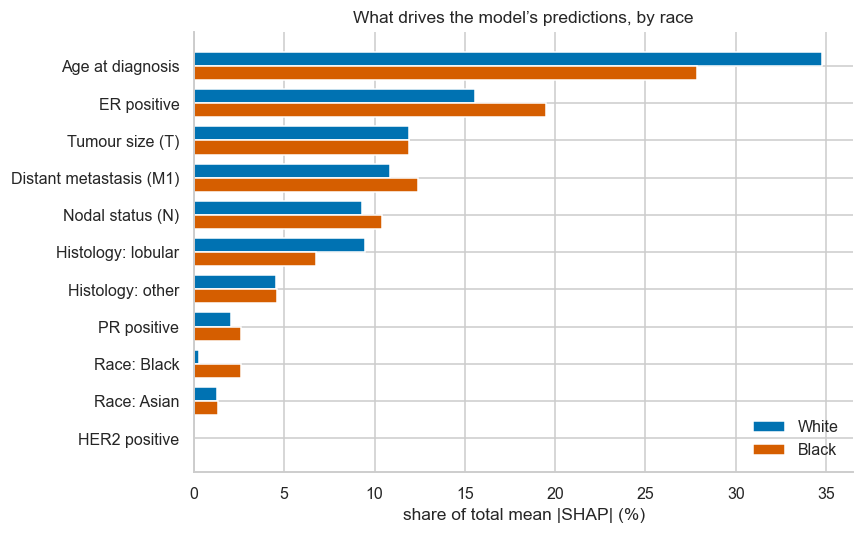

In [22]:
def share(mask):                       # normalised mean |SHAP| (importance shares sum to 1)
    v = np.abs(SHAP.values[mask]).mean(0); return v / v.sum()
sh_b, sh_w = share(is_black), share(is_white)

# bootstrap CI for the difference in importance share (patients resampled; model and SHAP values fixed)
r = np.random.default_rng(11); db = []
ib, iw = np.where(is_black)[0], np.where(is_white)[0]
for _ in range(1000):
    a, b = r.choice(ib, len(ib)), r.choice(iw, len(iw))
    va, vb = np.abs(SHAP.values[a]).mean(0), np.abs(SHAP.values[b]).mean(0); db.append(va / va.sum() - vb / vb.sum())
db = np.array(db)
cmp_tbl = pd.DataFrame({"Black share": sh_b, "White share": sh_w, "diff (B−W)": sh_b - sh_w,
                        "CI lo": np.percentile(db, 2.5, 0), "CI hi": np.percentile(db, 97.5, 0)}, index=[LABELS[f] for f in FEATURES])
MAT_SHARE, MAT_LOGODDS = 0.02, 0.05          # materiality: CI must exclude 0 AND the effect must be big enough to matter
cmp_tbl["sig"] = np.where(((cmp_tbl["CI lo"] > 0) | (cmp_tbl["CI hi"] < 0)) & (cmp_tbl["diff (B−W)"].abs() >= MAT_SHARE), "★", "")
print(f"★ = 95% CI excludes 0 AND |difference| ≥ {MAT_SHARE:.2f} share points (a CI that excludes 0 for a 0.002 difference is statistically, not practically, significant).")
display(cmp_tbl.sort_values("Black share", ascending=False).round(3))

order = np.argsort(-(sh_b + sh_w))
fig, ax = plt.subplots(figsize=(8, 5)); yy = np.arange(len(order)); h = 0.38
ax.barh(yy - h/2, sh_w[order] * 100, h, color=RC["White"], label="White"); ax.barh(yy + h/2, sh_b[order] * 100, h, color=RC["Black"], label="Black")
ax.set_yticks(yy); ax.set_yticklabels([LABELS[FEATURES[i]] for i in order]); ax.invert_yaxis()
ax.set(xlabel="share of total mean |SHAP| (%)", title="What drives the model’s predictions, by race"); ax.legend(frameon=False)
plt.tight_layout(); savefig("10_importance_black_vs_white"); plt.show()

### 8.2 SHAP summary restricted to Black patients
Same model, same scale — only the patients plotted change.

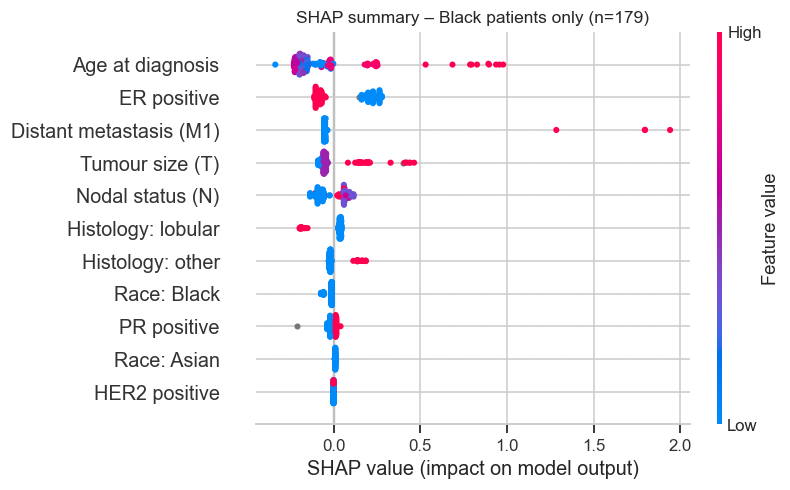

In [23]:
plt.figure(figsize=(7.5, 4.6)); shap.plots.beeswarm(sv_d[is_black], max_display=12, show=False, plot_size=None)
plt.title(f"SHAP summary – Black patients only (n={is_black.sum()})"); plt.tight_layout(); savefig("11_beeswarm_black"); plt.show()

### 8.3 Decomposing the *risk gap*: why does the model score the average Black patient differently from the average White patient?

Because SHAP is additive, the difference in **mean log-odds** between two groups splits exactly into per-feature pieces:

$$\overline{\mathrm{logit}}_{\text{Black}}-\overline{\mathrm{logit}}_{\text{White}}=\sum_j\big(\bar\phi_j^{\text{Black}}-\bar\phi_j^{\text{White}}\big)$$

Each term answers: *“how much of the gap is the model reading off feature j?”* (Positive ⇒ pushes Black patients’ predicted risk up relative to White patients.) Patient-level bootstrap gives 95 % CIs.

,mean φ Black,mean φ White,contribution to gap,lo,hi,sig,odds ratio exp(Δφ)
Age at diagnosis,-0.061,-0.037,-0.024,-0.067,0.021,,0.977
Race: Black,-0.019,0.002,-0.021,-0.024,-0.018,,0.980
Nodal status (N),-0.009,-0.003,-0.007,-0.020,0.006,,0.993
PR positive,-0.006,0.001,-0.006,-0.010,-0.003,,0.994
Tumour size (T),-0.013,-0.010,-0.004,-0.022,0.015,,0.996
Histology: other,-0.004,-0.001,-0.003,-0.011,0.006,,0.997
HER2 positive,0.000,0.000,0.000,0.000,0.000,,1.000
Race: Asian,0.010,0.009,0.000,0.000,0.000,,1.000
Distant metastasis (M1),-0.013,-0.021,0.008,-0.028,0.052,,1.008
Histology: lobular,0.022,-0.010,0.032,0.021,0.043,,1.033


★ = CI excludes 0 AND |Δφ| ≥ 0.05 log-odds.
Total gap in mean log-odds (Black − White) = +0.027   → mean predicted risk Black 14.7% vs White 14.5%


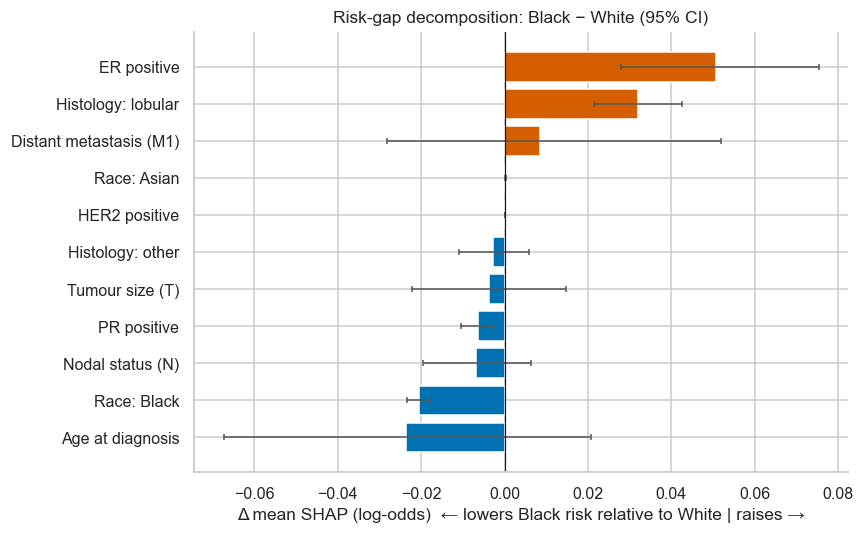

In [24]:
r = np.random.default_rng(5); gb = []
for _ in range(2000):
    a, b = r.choice(ib, len(ib)), r.choice(iw, len(iw)); gb.append(SHAP.values[a].mean(0) - SHAP.values[b].mean(0))
gb = np.array(gb)
gap = pd.DataFrame({"mean φ Black": SHAP.values[is_black].mean(0), "mean φ White": SHAP.values[is_white].mean(0)}, index=FEATURES)
gap["contribution to gap"] = gap["mean φ Black"] - gap["mean φ White"]
gap["lo"], gap["hi"] = np.percentile(gb, 2.5, 0), np.percentile(gb, 97.5, 0)
gap["sig"] = np.where(((gap.lo > 0) | (gap.hi < 0)) & (gap["contribution to gap"].abs() >= MAT_LOGODDS), "★", "")
gap["odds ratio exp(Δφ)"] = np.exp(gap["contribution to gap"])
gap_d = gap.rename(index=LABELS).sort_values("contribution to gap")
display(gap_d.round(3))
lg_gap = gap["contribution to gap"].sum()
print(f"★ = CI excludes 0 AND |Δφ| ≥ {MAT_LOGODDS} log-odds.")
print(f"Total gap in mean log-odds (Black − White) = {lg_gap:+.3f}   → mean predicted risk Black {p_final[is_black].mean():.1%} vs White {p_final[is_white].mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 5))
d = gap_d["contribution to gap"]; cols = [RC["Black"] if v > 0 else RC["White"] for v in d]
ax.barh(d.index, d.values, color=cols, xerr=[d.values - gap_d["lo"].values, gap_d["hi"].values - d.values], error_kw=dict(ecolor="#555", lw=1, capsize=2))
ax.axvline(0, c="k", lw=0.8); ax.set(xlabel="Δ mean SHAP (log-odds)  ← lowers Black risk relative to White | raises →", title="Risk-gap decomposition: Black − White (95% CI)")
plt.tight_layout(); savefig("12_risk_gap_decomposition"); plt.show()

### 8.4 The direct role of the race variable (two complementary tests)

1. **SHAP value of “Race: Black”** among Black patients – how many log-odds the model adds/subtracts *because the race flag is 1*.
2. **Counterfactual flip** – keep every other clinical value fixed, switch the race flag from Black to White and re-predict. The change in predicted risk is the model’s *direct* race sensitivity.

If both are near zero with CIs straddling zero, the model is **not using the race flag**; any difference between groups is mediated through clinical variables (age at diagnosis, receptor status, nodal burden …).

,value
mean φ(Race: Black) among Black patients [log-odds],"-0.019 (95% CI -0.022, -0.016)"
share of Black patients with φ>0,0%
mean Δ predicted risk if recorded White [pct-points],"-0.30 (95% CI -0.42, -0.20)"
largest single-patient |Δ risk| [pct-points],3.1
race flag's rank by mean|SHAP| (1 = most important of 11),10


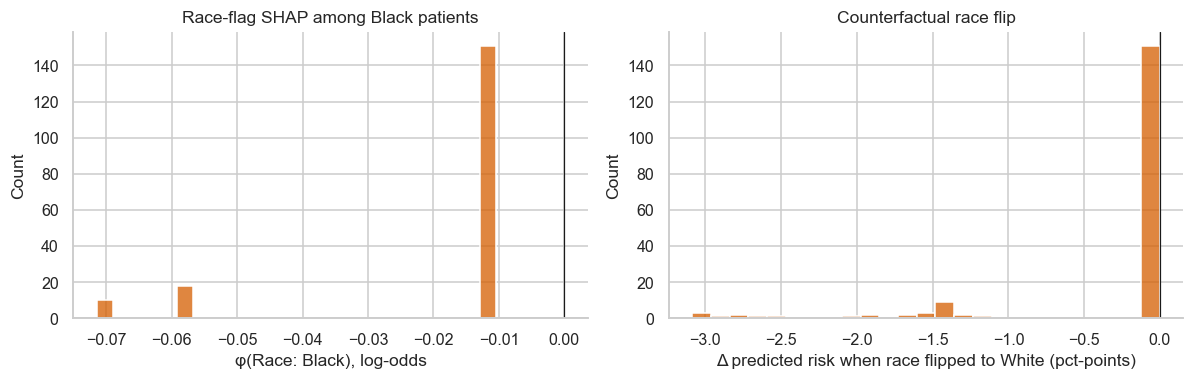

In [25]:
phi_race = SHAP["race_black"].values[is_black]
Xcf = X.copy(); Xcf["race_black"] = 0.0
delta = (final.predict_proba(X)[:, 1] - final.predict_proba(Xcf)[:, 1])[is_black]
bs_phi = [rng.choice(phi_race, len(phi_race)).mean() for _ in range(2000)]
bs_del = [rng.choice(delta, len(delta)).mean() for _ in range(2000)]
race_tbl = pd.DataFrame({
    "mean φ(Race: Black) among Black patients [log-odds]": f"{phi_race.mean():+.3f}  (95% CI {np.percentile(bs_phi,2.5):+.3f}, {np.percentile(bs_phi,97.5):+.3f})",
    "share of Black patients with φ>0": f"{(phi_race > 0).mean():.0%}",
    "mean Δ predicted risk if recorded White [pct-points]": f"{100*delta.mean():+.2f}  (95% CI {100*np.percentile(bs_del,2.5):+.2f}, {100*np.percentile(bs_del,97.5):+.2f})",
    "largest single-patient |Δ risk| [pct-points]": f"{100*np.abs(delta).max():.1f}",
    f"race flag's rank by mean|SHAP| (1 = most important of {len(FEATURES)})": int(pd.Series(np.abs(SHAP.values).mean(0), index=FEATURES).rank(ascending=False)["race_black"]),
}, index=["value"]).T
display(race_tbl)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(phi_race, bins=25, color=RC["Black"], ax=ax[0]); ax[0].axvline(0, c="k", lw=.8); ax[0].set(xlabel="φ(Race: Black), log-odds", title="Race-flag SHAP among Black patients")
sns.histplot(100 * delta, bins=25, color=RC["Black"], ax=ax[1]); ax[1].axvline(0, c="k", lw=.8); ax[1].set(xlabel="Δ predicted risk when race flipped to White (pct-points)", title="Counterfactual race flip")
plt.tight_layout(); savefig("13_race_direct_effect"); plt.show()

### 8.5 Does the *shape* of an effect differ by race?
Binned mean SHAP (±95 % CI) for the key continuous/ordinal features, Black vs. White. Overlapping bands ⇒ the model treats the feature the same way for both groups.

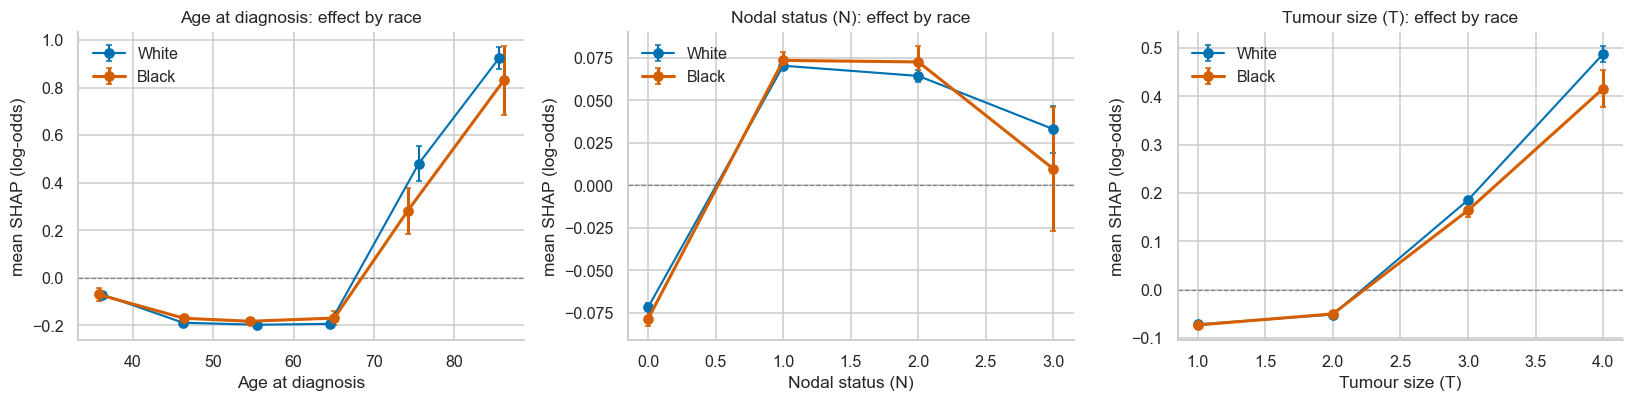

In [26]:
def binned(feat, mask, bins):
    x, v = X.loc[mask, feat].values, SHAP.loc[mask, feat].values; ok = ~np.isnan(x)
    cat = pd.cut(x[ok], bins, include_lowest=True); d_ = pd.DataFrame({"b": cat, "v": v[ok], "x": x[ok]})
    g_ = d_.groupby("b", observed=True).agg(x=("x", "mean"), m=("v", "mean"), s=("v", "std"), n=("v", "size"))
    g_["ci"] = 1.96 * g_.s / np.sqrt(g_.n); return g_[g_.n >= 4]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax_, (f, bins) in zip(axes, [("age", [20, 40, 50, 60, 70, 80, 95]), ("n_stage", [-.5, .5, 1.5, 2.5, 3.5]), ("t_stage", [.5, 1.5, 2.5, 3.5, 4.5])]):
    for r_, mask in [("White", is_white), ("Black", is_black)]:
        b_ = binned(f, mask, bins); ax_.errorbar(b_.x, b_.m, yerr=b_.ci, color=RC[r_], marker="o", capsize=2, label=r_, lw=2 if r_ == "Black" else 1.4)
    ax_.axhline(0, c="grey", lw=.8, ls="--"); ax_.set(xlabel=LABELS[f], ylabel="mean SHAP (log-odds)", title=f"{LABELS[f]}: effect by race"); ax_.legend(frameon=False)
plt.tight_layout(); savefig("14_effect_shape_by_race"); plt.show()

### 8.6 Error analysis – what is the model missing in Black patients?
False negatives (died but scored below threshold) are the costly error. Mean SHAP profile of missed vs. caught deaths among Black patients, and of White for reference:

In [27]:
rows = {}
for r_, mask in [("Black", is_black), ("White", is_white)]:
    d_ = clean[mask & (y == 1)]
    caught, missed = d_.risk_oof >= THR_OOF, d_.risk_oof < THR_OOF
    rows[f"{r_}: caught (n={caught.sum()})"] = SHAP.loc[d_.index[caught.values]].mean()
    rows[f"{r_}: missed (n={missed.sum()})"] = SHAP.loc[d_.index[missed.values]].mean()
err = pd.DataFrame(rows); err.index = [LABELS[f] for f in err.index]
display(err.round(2).style.background_gradient(cmap="RdBu_r", axis=None, vmin=-1.2, vmax=1.2))
prof = clean[is_black & (y == 1)].assign(missed=lambda d: d.risk_oof < THR_OOF).groupby("missed")[["age", "t_stage", "n_stage", "er_pos", "pr_pos", "her2_pos"]].mean().round(2)
prof.index = ["caught", "missed"]; print("Clinical profile of Black patients who died — caught vs. missed:"); display(prof)

,Black: caught (n=24),Black: missed (n=5),White: caught (n=89),White: missed (n=22)
Age at diagnosis,0.070000,-0.190000,0.170000,-0.190000
Race: Black,-0.030000,-0.010000,0.000000,0.000000
Race: Asian,0.010000,0.010000,0.010000,0.010000
Tumour size (T),0.020000,0.040000,0.060000,-0.060000
Nodal status (N),0.010000,-0.050000,0.040000,-0.040000
Distant metastasis (M1),0.190000,-0.050000,0.180000,-0.050000
ER positive,0.130000,-0.080000,0.010000,-0.050000
PR positive,-0.000000,0.010000,0.000000,0.000000
HER2 positive,0.000000,0.000000,0.000000,0.000000
Histology: lobular,0.020000,0.040000,0.010000,0.000000


Clinical profile of Black patients who died — caught vs. missed:


,age,t_stage,n_stage,er_pos,pr_pos,her2_pos
caught,58.54,2.08,1.09,0.33,0.33,0.12
missed,56.80,1.75,0.33,1.00,1.00,NaN


### 8.7 What does the race flag add? Race-blind twin model

A recurring question in clinical-AI audits: *if we simply remove race, does the model get worse — or fairer?* I retrain the identical model on `FEATURES_NO_RACE` and compare discrimination, subgroup recall, and the attribution profile for Black patients.

In [28]:
nr = make_model().fit(X_tr[FEATURES_NO_RACE], y_tr)         # same params, train split (for SHAP profile)
exp_nr = shap.TreeExplainer(make_model().fit(X[FEATURES_NO_RACE], y)); sv_nr = exp_nr(X[FEATURES_NO_RACE])
tab = []
for tag, col in [("with race", "risk_oof"), ("race-blind", "risk_oof_norace")]:
    for r_, mask in [("Black", is_black), ("White", is_white)]:
        m = metrics(y[mask], clean[col].values[mask], THR_OOF if col == "risk_oof" else float(roc_curve(y, clean[col])[2][np.argmax(roc_curve(y, clean[col])[1] >= TARGET_RECALL)]))
        tab.append({"model": tag, "group": r_, "AUC": m["AUC"], "Recall": m["Recall"], "Specificity": m["Specificity"], "mean pred": m["MeanPred"]})
display(pd.DataFrame(tab).round(3).set_index(["model", "group"]))
# attribution shares for Black patients: with vs without race
v1 = pd.Series(sh_b, index=FEATURES)
v2 = pd.Series(np.abs(sv_nr.values[is_black]).mean(0), index=FEATURES_NO_RACE); v2 /= v2.sum()
cmp2 = pd.DataFrame({"with race": v1, "race-blind": v2}).fillna(0).rename(index=LABELS)
rho_nr = stats.spearmanr(cmp2.drop(index=["Race: Black", "Race: Asian"])["with race"], cmp2.drop(index=["Race: Black", "Race: Asian"])["race-blind"])[0]
display(cmp2.round(3).sort_values("with race", ascending=False))
print(f"Spearman rank agreement of Black-patient attributions on the 10 shared features: {rho_nr:.2f}")

AUC  Recall  Specificity  mean pred
model      group                                       
with race  Black  0.609   0.828        0.227      0.151
           White  0.655   0.802        0.332      0.144
race-blind Black  0.613   0.793        0.253      0.148
           White  0.654   0.802        0.316      0.142

,with race,race-blind
Age at diagnosis,0.278,0.321
ER positive,0.195,0.144
Distant metastasis (M1),0.124,0.136
Tumour size (T),0.119,0.134
Nodal status (N),0.104,0.201
Histology: lobular,0.068,0.025
Histology: other,0.046,0.026
Race: Black,0.026,0.000
PR positive,0.026,0.008
Race: Asian,0.013,0.000


Spearman rank agreement of Black-patient attributions on the 10 shared features: 0.88


## 9. Can we trust the explanations? Stability (Objective 3 / §2.3 “SHAP consistency & stability”)

With ~29 events in the Black subgroup, a model re-trained on a slightly different sample could tell a different story. I re-train the model on **100 stratified bootstrap resamples** of the cohort and recompute the SHAP profile for Black patients each time. Narrow bands and a stable top-k ranking mean the explanation is a property of the data, not of one lucky fit.

,importance share (median),2.5%,97.5%,median rank,P(top-3)
Age at diagnosis,0.308,0.145,0.505,1.0,0.98
Nodal status (N),0.172,0.024,0.317,3.0,0.70
Distant metastasis (M1),0.121,0.041,0.208,4.0,0.44
Tumour size (T),0.119,0.037,0.256,4.0,0.45
ER positive,0.100,0.013,0.235,4.5,0.32
PR positive,0.025,0.005,0.122,7.0,0.03
Histology: lobular,0.025,0.001,0.104,8.0,0.01
Histology: other,0.023,0.000,0.149,7.5,0.07
Race: Asian,0.013,0.004,0.026,9.0,0.00
Race: Black,0.012,0.000,0.070,9.0,0.00


mean pairwise Spearman of Black-patient SHAP rankings across bootstraps: 0.68  (1 = identical every time)
top-3 by median importance share: ['Age at diagnosis', 'Nodal status (N)', 'Distant metastasis (M1)']


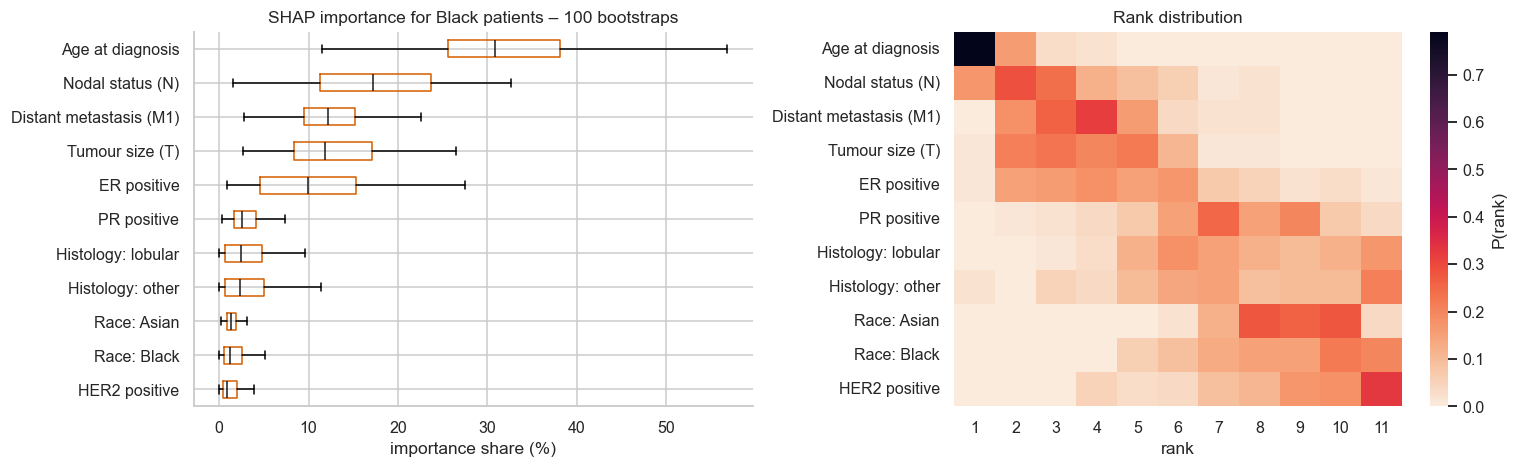

In [29]:
B = 100; rb = np.random.default_rng(2024)
imp_b = np.zeros((B, len(FEATURES))); signed_b = np.zeros((B, len(FEATURES))); rank_b = np.zeros((B, len(FEATURES)), int)
labels_u = np.unique(strata)
for b_ in range(B):
    idx = np.concatenate([rb.choice(np.where(strata == s)[0], (strata == s).sum()) for s in labels_u])
    m = make_model(seed=int(rb.integers(1e6))).fit(X.iloc[idx], y[idx])
    sv_b = shap.TreeExplainer(m).shap_values(X[is_black])
    a = np.abs(sv_b).mean(0); imp_b[b_] = a / a.sum(); signed_b[b_] = sv_b.mean(0)
    rank_b[b_] = (-a).argsort().argsort() + 1
stab = pd.DataFrame({"importance share (median)": np.median(imp_b, 0), "2.5%": np.percentile(imp_b, 2.5, 0), "97.5%": np.percentile(imp_b, 97.5, 0),
                     "median rank": np.median(rank_b, 0), "P(top-3)": (rank_b <= 3).mean(0)}, index=[LABELS[f] for f in FEATURES]).sort_values("importance share (median)", ascending=False)
display(stab.round(3))
# overall ranking stability: mean pairwise Spearman among bootstrap rankings
pair = [stats.spearmanr(imp_b[i], imp_b[j])[0] for i in range(0, B, 2) for j in range(1, B, 2) if i != j]
print(f"mean pairwise Spearman of Black-patient SHAP rankings across bootstraps: {np.mean(pair):.2f}  (1 = identical every time)")
top3 = stab.index[:3].tolist(); print("top-3 by median importance share:", top3)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
o = np.argsort(-np.median(imp_b, 0))
ax[0].boxplot(imp_b[:, o] * 100, vert=False, labels=[LABELS[FEATURES[i]] for i in o], showfliers=False, boxprops=dict(color=RC["Black"]), medianprops=dict(color="k"))
ax[0].invert_yaxis(); ax[0].set(xlabel="importance share (%)", title="SHAP importance for Black patients – 100 bootstraps")
H = np.array([[(rank_b[:, j] == k).mean() for k in range(1, len(FEATURES) + 1)] for j in o])
sns.heatmap(H, cmap="rocket_r", ax=ax[1], yticklabels=[LABELS[FEATURES[i]] for i in o], xticklabels=range(1, len(FEATURES) + 1), cbar_kws={"label": "P(rank)"})
ax[1].set(xlabel="rank", title="Rank distribution")
plt.tight_layout(); savefig("15_stability_black"); plt.show()

### 9.1 Clinical-alignment check (“do SHAP explanations match established medical knowledge?”)

For features with a well-established direction of effect, I test whether the SHAP value moves the *expected* way as the feature increases (Spearman correlation between feature value and its SHAP value; patients with the feature missing are excluded). Expected: older age, larger tumour, more nodes, metastasis → higher risk; ER/PR-positive → lower risk.

In [30]:
rows = []
for f, sgn in CLINICAL_PRIOR.items():
    for grp, mask in [("All", np.ones(len(y), bool)), ("Black", is_black), ("White", is_white)]:
        ok = mask & X[f].notna().values
        if X.loc[ok, f].nunique() < 2: continue
        rho_, p_ = stats.spearmanr(X.loc[ok, f], SHAP.loc[ok, f])
        rows.append({"feature": LABELS[f], "group": grp, "expected": "↑ risk" if sgn > 0 else "↓ risk", "Spearman ρ (value, SHAP)": round(rho_, 2),
                     "agrees": "✓" if np.sign(rho_) == sgn else "✗", "p": f"{p_:.1g}",
                     "importance share": round(float(np.abs(SHAP.loc[mask, f]).mean() / np.abs(SHAP.loc[mask].values).mean(0).sum()), 3)})
align = pd.DataFrame(rows)
display(align.pivot(index=["feature", "expected"], columns="group", values="agrees"))
display(align.set_index(["feature", "group"]).drop(columns="expected"))
pr_ = clean.assign(PR=clean.pr_pos.map({1.0: "PR+", 0.0: "PR−"})).groupby(["er_pos", "PR"]).agg(n=(TARGET, "size"), death_rate=(TARGET, "mean")).round(3)
print("PR check — marginal death rate by ER×PR (short follow-up; ER+PR− and ER+PR+ are indistinguishable, so the model has no PR signal to learn):"); display(pr_.T)

,group,All,Black,White
feature,expected,,,
Age at diagnosis,↑ risk,✓,✓,✓
Distant metastasis (M1),↑ risk,✓,✓,✓
ER positive,↓ risk,✓,✓,✓
Nodal status (N),↑ risk,✓,✓,✓
PR positive,↓ risk,✗,✗,✗
Tumour size (T),↑ risk,✓,✓,✓


Spearman ρ (value, SHAP) agrees       p  \
feature                 group                                            
Age at diagnosis        All                        0.20      ✓   2e-10   
                        Black                      0.20      ✓   0.006   
                        White                      0.23      ✓   1e-10   
Tumour size (T)         All                        0.85      ✓  2e-276   
                        Black                      0.87      ✓   1e-54   
                        White                      0.85      ✓  2e-211   
Nodal status (N)        All                        0.75      ✓  2e-178   
                        Black                      0.75      ✓   1e-33   
                        White                      0.75      ✓  4e-134   
Distant metastasis (M1) All                        0.22      ✓   3e-12   
                        Black                      0.26      ✓  0.0005   
                        White                      0.22      ✓   2e-09   
ER positive             All                       -0.74      ✓  2e-163   
                        Black                     -0.85      ✓   2e-49   
                        White                     -0.69      ✓   5e-99   
PR positive             All                        0.83      ✗  2e-232   
                        Black                      0.87      ✗   6e-56   
                        White                      0.79      ✗  8e-153   

                               importance share  
feature                 group                    
Age at diagnosis        All               0.331  
                        Black             0.278  
                        White             0.348  
Tumour size (T)         All               0.118  
                        Black             0.119  
                        White             0.119  
Nodal status (N)        All               0.095  
                        Black             0.104  
                        White             0.093  
Distant metastasis (M1) All               0.108  
                        Black             0.124  
                        White             0.109  
ER positive             All               0.164  
                        Black             0.195  
                        White             0.156  
PR positive             All               0.021  
                        Black             0.026  
                        White             0.021

PR check — marginal death rate by ER×PR (short follow-up; ER+PR− and ER+PR+ are indistinguishable, so the model has no PR signal to learn):


er_pos         0.0               1.0        
PR             PR+      PR−      PR+     PR−
n           15.000  208.000  594.000  108.00
death_rate   0.067    0.183    0.135    0.12

## 10. Sensitivity: does the story survive a different outcome definition?

“Died during follow-up” mixes people followed for 3 years with people followed for 15. As a robustness check I rebuild the label as **death within 24 / 36 / 60 months**, keeping only patients whose status at the horizon is *known* (died ≤ horizon, or followed ≥ horizon). Patients censored earlier are dropped, so the cohort — and especially the Black subgroup — shrinks. Same pipeline → does discrimination hold, and is the SHAP ranking similar?

In [31]:
strata_all = pd.Series(strata, index=clean.index)
sens_rows, sens_imp = [], {}
for h in [24, 36, 60]:
    known = (((clean[TARGET] == 1) & (clean.os_months <= h)) | (clean.os_months >= h)).values
    yh = ((clean[TARGET] == 1) & (clean.os_months <= h)).astype(int).values[known]
    Xh, bh = X[known], is_black[known]
    st_h = (clean.race[known].astype(str) + "_" + pd.Series(yh, index=clean.index[known]).astype(str)).values
    oof_h = np.zeros(len(yh))
    for a_, b_ in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xh, st_h):
        oof_h[b_] = make_model().fit(Xh.iloc[a_], yh[a_]).predict_proba(Xh.iloc[b_])[:, 1]
    mh = make_model().fit(Xh, yh); ah = np.abs(shap.TreeExplainer(mh).shap_values(Xh[bh])).mean(0); ah = ah / ah.sum()
    sens_imp[h] = ah
    wh = (clean.race[known] == "White").values
    sens_rows.append({"horizon (months)": h, "n": len(yh), "events": int(yh.sum()), "Black n": int(bh.sum()), "Black events": int(yh[bh].sum()),
                      "OOF AUC all": roc_auc_score(yh, oof_h), "AUC Black": roc_auc_score(yh[bh], oof_h[bh]), "AUC White": roc_auc_score(yh[wh], oof_h[wh]),
                      "ρ(Black SHAP ranking vs primary)": stats.spearmanr(sh_b, ah)[0]})
display(pd.DataFrame(sens_rows).set_index("horizon (months)").round(2))
sens = pd.DataFrame({"primary outcome": sh_b, **{f"{h}-month": v for h, v in sens_imp.items()}}, index=[LABELS[f] for f in FEATURES])
sens["36-month"] = sens["36-month"]
t3a, t3b = set(sens["primary outcome"].nlargest(3).index), set(sens["36-month"].nlargest(3).index)
print("top-3 (primary):", sorted(t3a), "| top-3 (36-month):", sorted(t3b), "| overlap:", sorted(t3a & t3b))
sens_rho = stats.spearmanr(sens["primary outcome"], sens["36-month"])[0]
display(sens.sort_values("primary outcome", ascending=False).round(3))

,n,events,Black n,Black events,OOF AUC all,AUC Black,AUC White,ρ(Black SHAP ranking vs primary)
horizon (months),,,,,,,,
24,587,36,104,8,0.67,0.65,0.67,0.49
36,472,64,84,14,0.71,0.65,0.72,0.64
60,334,93,59,17,0.72,0.64,0.73,0.57


top-3 (primary): ['Age at diagnosis', 'Distant metastasis (M1)', 'ER positive'] | top-3 (36-month): ['Age at diagnosis', 'Nodal status (N)', 'Tumour size (T)'] | overlap: ['Age at diagnosis']


,primary outcome,24-month,36-month,60-month
Age at diagnosis,0.278,0.307,0.258,0.337
ER positive,0.195,0.069,0.135,0.114
Distant metastasis (M1),0.124,0.022,0.047,0.041
Tumour size (T),0.119,0.206,0.136,0.076
Nodal status (N),0.104,0.189,0.211,0.215
Histology: lobular,0.068,0.013,0.002,0.007
Histology: other,0.046,0.009,0.004,0.006
Race: Black,0.026,0.027,0.063,0.015
PR positive,0.026,0.122,0.133,0.155
Race: Asian,0.013,0.000,0.000,0.000


## 11. Export artefacts for the dashboard (and the user study)

The dashboard (`app.py`) is a thin, fast layer over what is produced here: the trained model, the cohort with per-patient SHAP values and out-of-fold risks, the threshold, and the audit tables. Nothing in it is re-fitted at run-time, so every number you see in the dashboard is traceable to a cell in this notebook.

In [32]:
# race-blind final model (used by the dashboard's "remove race" switch)
final_nr = make_model().fit(X[FEATURES_NO_RACE], y)
final.save_model(ART / "xgb_model.json"); final_nr.save_model(ART / "xgb_model_norace.json")

cohort = clean.drop(columns=["race_full"]).copy()
for f in FEATURES: cohort[f"x_{f}"] = X[f].values
for f in FEATURES: cohort[f"shap_{f}"] = SHAP[f].values
cohort["shap_base"] = float(sv.base_values[0])
cohort.to_csv(ART / "cohort.csv", index=False)

# curves & audit tables for the dashboard
fprA, tprA, _ = roc_curve(y, clean.risk_oof)
meta = {
    "features": FEATURES, "labels": LABELS, "race_features": RACE_FEATURES, "features_no_race": FEATURES_NO_RACE,
    "threshold_train_oof": THR, "threshold_all_oof": THR_OOF, "target_recall": TARGET_RECALL, "base_value": float(sv.base_values[0]),
    "best_params": best, "n_trees": BEST_N, "seed": SEED, "target": "died (TCGA overall-survival event)",
    "n_patients": int(len(y)), "n_events": int(y.sum()),
    "test_metrics": {k: float(m_te[k]) for k in keys}, "test_n": int(len(y_te)),
    "oof_auc_overall": float(roc_auc_score(y, clean.risk_oof)),
    "versions": {"xgboost": xgb.__version__, "shap": shap.__version__, "sklearn": sklearn.__version__},
}
json.dump(meta, open(ART / "meta.json", "w"), indent=2)
cmp_tbl.to_csv(ART / "importance_black_vs_white.csv")
gap.rename(index=LABELS).to_csv(ART / "risk_gap_decomposition.csv")
stab.to_csv(ART / "stability_black.csv")
perf_by_race.to_csv(ART / "performance_by_race.csv")
t1.to_csv(ART / "table1.csv")
pd.DataFrame({"threshold": ths, **{f"recall_{r_}": [((clean.risk_oof.values[m_] >= t) & (y[m_] == 1)).sum() / y[m_].sum() for t in ths] for r_, m_ in [("White", is_white), ("Black", is_black)]}}).to_csv(ART / "recall_vs_threshold.csv", index=False)
print("saved:", sorted(p.name for p in ART.iterdir()))

saved: ['cohort.csv', 'importance_black_vs_white.csv', 'meta.json', 'performance_by_race.csv', 'recall_vs_threshold.csv', 'risk_gap_decomposition.csv', 'stability_black.csv', 'table1.csv', 'xgb_model.json', 'xgb_model_norace.json']


## 12. Findings (generated from the results above, so the numbers cannot drift from the analysis)

In [33]:
fi = lambda f: LABELS[f]
imp_all = pd.Series(np.abs(SHAP.values).mean(0), index=[fi(f) for f in FEATURES]).sort_values(ascending=False)
top_b = pd.Series(sh_b, index=[fi(f) for f in FEATURES]).sort_values(ascending=False)
sig_gap = gap_d[gap_d.sig == "★"]
up = [f"{i} ({v:+.2f})" for i, v in sig_gap["contribution to gap"].items() if v > 0]
down = [f"{i} ({v:+.2f})" for i, v in sig_gap["contribution to gap"].items() if v < 0]
sig_diff = [f"{i} ({cmp_tbl.loc[i,'diff (B−W)']:+.2f})" for i in cmp_tbl[cmp_tbl.sig == "★"].index]
n_ok = int((align[align.group == "Black"].agrees == "✓").sum()); n_all = int((align.group == "Black").sum())
bad = align[(align.group == "Black") & (align.agrees == "✗")]
race_rank = int(pd.Series(np.abs(SHAP.values).mean(0), index=FEATURES).rank(ascending=False)["race_black"])
sd = pd.DataFrame(sens_rows)
sign_word = "lower" if delta.mean() < 0 else "higher"
fpr_ci = (np.percentile(g["FPR"], 2.5), np.percentile(g["FPR"], 97.5))
display(Markdown(f"""
**Model performance (Objective 2).** On the untouched test split (n={len(y_te)}, {int(y_te.sum())} deaths) the tuned XGBoost reaches AUC **{fmt(m_te, b_te, 'AUC')}**, recall **{fmt(m_te, b_te, 'Recall')}** and specificity **{fmt(m_te, b_te, 'Specificity')}** at the recall-first threshold. Out-of-fold over all {len(y)} patients the AUC is **{roc_auc_score(y, clean.risk_oof):.2f}**. These are *modest* numbers — realistic for routine clinical variables, ~{int(y.sum())} events and short follow-up — and far below the 97–99 % figures in the benign/malignant WBCD literature, which solve an easier, differently-posed task. A model with “not recorded” left as a signal scored **{abl.loc['AUC all','naive (leaky missingness)']:.2f}** — that extra {abl.loc['AUC all','naive (leaky missingness)']-abl.loc['AUC all','protected (final)']:.2f} AUC was a registry artefact, not clinical knowledge (§1.2, §6.2).

**What drives predictions overall (Objective 3).** {', '.join(f'{k} ({v:.2f})' for k, v in imp_all.head(4).items())} (mean |SHAP|, log-odds). SHAP, gain and permutation rankings agree (Spearman {rho.loc['SHAP mean|φ|','XGB gain']:.2f} / {rho.loc['SHAP mean|φ|','Permutation ΔAUC (test)']:.2f}). {n_ok} of {n_all} clinically-expected effect directions are reproduced among Black patients{'; the exception is ' + ', '.join(bad.feature.tolist()) + f' (only {100*bad["importance share"].mean():.0f}% of attribution, and no marginal PR signal in this short-follow-up data)' if len(bad) else ''}. HER2 carries no usable signal once its missingness artefact is removed.

**For Black patients (the question you asked).** The model leans mainly on **{', '.join(top_b.index[:3])}** ({', '.join(f'{v:.0%}' for v in top_b.head(3))} of attribution). Relative to White patients it relies *less* on age and *more* on ER status — features with a material, CI-excluding difference in importance share: {', '.join(sig_diff) if sig_diff else 'none'}. The two groups’ mean predicted risk is almost identical ({p_final[is_black].mean():.1%} vs {p_final[is_white].mean():.1%}); inside that near-zero gap the model *raises* Black risk through {', '.join(up) if up else 'no single feature'} (ER-negative disease is more common among Black patients) and partly offsets it through age ({gap.loc['age','contribution to gap']:+.2f}; the Black cohort is younger, CI includes 0) and the race flag ({gap.loc['race_black','contribution to gap']:+.2f}; below the materiality bar).

**The race flag itself.** It ranks {race_rank} of {len(FEATURES)} in importance. Re-labelling a Black patient as White would change the predicted risk by {100*delta.mean():+.2f} pct-points on average (95% CI {100*np.percentile(bs_del,2.5):+.2f}, {100*np.percentile(bs_del,97.5):+.2f}; max single patient {100*np.abs(delta).max():.1f}) — i.e. the model gives Black patients a very slightly **{sign_word}** score for the flag alone, which is a clinically negligible but non-zero direct use of race. Dropping the flag changes OOF AUC from {roc_auc_score(y, clean.risk_oof):.3f} to {roc_auc_score(y, clean.risk_oof_norace):.3f}: race adds nothing measurable to accuracy, which is an argument for excluding it from any deployed version.

**Equity of errors.** At one global threshold, recall is {mB['Recall']:.0%} (Black) vs {mW['Recall']:.0%} (White): gap {mB['Recall']-mW['Recall']:+.0%} (95% CI {np.percentile(g['Recall'],2.5):+.0%} to {np.percentile(g['Recall'],97.5):+.0%}). The false-positive rate is higher for Black patients ({mB['FPR']:.0%} vs {mW['FPR']:.0%}; gap {mB['FPR']-mW['FPR']:+.0%}, 95% CI {fpr_ci[0]:+.0%} to {fpr_ci[1]:+.0%}) — the model separates risk less sharply for them (AUC {mB['AUC']:.2f} vs {mW['AUC']:.2f}, CI of the gap includes 0). Four metrics were compared without multiplicity correction, so treat the FPR gap as a flag for follow-up, not a verdict.

**How much to trust the Black-subgroup explanations.** Across 100 bootstraps only **Age** is reliably in the top three (P = {stab.loc['Age at diagnosis','P(top-3)']:.2f}); the others fluctuate (mean pairwise rank correlation {np.mean(pair):.2f}). Re-defining the outcome as death within 24/36/60 months leaves the *model’s* AUC similar ({', '.join(f'{r:.2f}' for r in sd['OOF AUC all'])}) but the Black-patient feature ranking agrees only moderately with the primary one (ρ = {', '.join(f'{r:.2f}' for r in sd['ρ(Black SHAP ranking vs primary)'])}). With {int(y[is_black].sum())} events, the subgroup SHAP picture is **suggestive, not established**.
"""))


**Model performance (Objective 2).** On the untouched test split (n=197, 29 deaths) the tuned XGBoost reaches AUC **0.74 (0.63–0.84)**, recall **0.93 (0.83–1.00)** and specificity **0.25 (0.19–0.32)** at the recall-first threshold. Out-of-fold over all 982 patients the AUC is **0.65**. These are *modest* numbers — realistic for routine clinical variables, ~143 events and short follow-up — and far below the 97–99 % figures in the benign/malignant WBCD literature, which solve an easier, differently-posed task. A model with “not recorded” left as a signal scored **0.77** — that extra 0.11 AUC was a registry artefact, not clinical knowledge (§1.2, §6.2).

**What drives predictions overall (Objective 3).** Age at diagnosis (0.25), ER positive (0.12), Tumour size (T) (0.09), Distant metastasis (M1) (0.08) (mean |SHAP|, log-odds). SHAP, gain and permutation rankings agree (Spearman 0.90 / 0.84). 5 of 6 clinically-expected effect directions are reproduced among Black patients; the exception is PR positive (only 3% of attribution, and no marginal PR signal in this short-follow-up data). HER2 carries no usable signal once its missingness artefact is removed.

**For Black patients (the question you asked).** The model leans mainly on **Age at diagnosis, ER positive, Distant metastasis (M1)** (28%, 20%, 12% of attribution). Relative to White patients it relies *less* on age and *more* on ER status — features with a material, CI-excluding difference in importance share: Age at diagnosis (-0.07), Race: Black (+0.02), ER positive (+0.04), Histology: lobular (-0.03). The two groups’ mean predicted risk is almost identical (14.7% vs 14.5%); inside that near-zero gap the model *raises* Black risk through ER positive (+0.05) (ER-negative disease is more common among Black patients) and partly offsets it through age (-0.02; the Black cohort is younger, CI includes 0) and the race flag (-0.02; below the materiality bar).

**The race flag itself.** It ranks 10 of 11 in importance. Re-labelling a Black patient as White would change the predicted risk by -0.30 pct-points on average (95% CI -0.42, -0.20; max single patient 3.1) — i.e. the model gives Black patients a very slightly **lower** score for the flag alone, which is a clinically negligible but non-zero direct use of race. Dropping the flag changes OOF AUC from 0.654 to 0.648: race adds nothing measurable to accuracy, which is an argument for excluding it from any deployed version.

**Equity of errors.** At one global threshold, recall is 83% (Black) vs 80% (White): gap +3% (95% CI -14% to +17%). The false-positive rate is higher for Black patients (77% vs 67%; gap +11%, 95% CI +3% to +18%) — the model separates risk less sharply for them (AUC 0.61 vs 0.66, CI of the gap includes 0). Four metrics were compared without multiplicity correction, so treat the FPR gap as a flag for follow-up, not a verdict.

**How much to trust the Black-subgroup explanations.** Across 100 bootstraps only **Age** is reliably in the top three (P = 0.98); the others fluctuate (mean pairwise rank correlation 0.68). Re-defining the outcome as death within 24/36/60 months leaves the *model’s* AUC similar (0.67, 0.71, 0.72) but the Black-patient feature ranking agrees only moderately with the primary one (ρ = 0.49, 0.64, 0.57). With 29 events, the subgroup SHAP picture is **suggestive, not established**.


## 13. Limitations, ethics and what to do next

**Limitations (be explicit about these in the thesis).**
* *Target substitution* — mortality rather than benign/malignant (see top of notebook). The pipeline is target-agnostic; if a dataset with benign lesions (e.g. WBCD, or a local hospital cohort) becomes available, only `load_clean()` changes.
* *Small, unequal subgroups* — ≈29 events among Black patients; the 36-month sensitivity set is smaller still. Intervals are wide; subgroup findings are hypotheses to validate, not conclusions.
* *Censoring & short follow-up* — TCGA follow-up is short (median ≈ 2 years). Death during follow-up is a lower bound on mortality and differs by site. A time-to-event model (Cox / survival-XGBoost) would use this information better; it was not used here because the proposal specifies a classification framing and SHAP for classifiers.
* *Association, not causation* — SHAP explains the model, not biology. Race in TCGA is self-reported; it proxies unmeasured social determinants (access, stage at presentation, treatment delays) and ancestry. Genetic ancestry labels exist in the cBioPortal table and would be a natural refinement.
* *Collinearity* — ER, PR, HER2 and age are correlated; SHAP divides credit among correlated features in a way that depends on the model (TreeSHAP’s path-dependent estimator), so individual attributions should be read together with the interaction view.
* *Single-source data* — TCGA is a convenience sample of treatment-naive, resected tumours from academic centres; it is not representative of Nigerian or general-population patients. External validation is required before any clinical use.

**Ethics (§3.2.8).** Only public, de-identified data are used; no attempt is made at re-identification; the dashboard is a *research instrument* and carries an explicit “not for clinical use” banner. Using race as a model input is **not recommended for deployment** without clinical governance — the race-blind twin (§8.7) shows what is gained or lost.

**Next steps.** (1) Run the physician user study with the dashboard (Objective 4); (2) add monotonic constraints from `CLINICAL_PRIOR` and check whether explanation stability improves; (3) validate on an external cohort (METABRIC is open); (4) try a survival objective (`survival:cox`) with SHAP; (5) pursue group-calibrated recalibration if the calibration slopes differ materially.

---
**Run the dashboard:** `streamlit run app.py`